# Parallel Computing Laboratory Record
## Complete Practical Notebook (All 10 Programs)

This laboratory notebook contains complete implementations, benchmark results, execution-time bar graphs, and speedup curves for 10 practical programs in Parallel Computing using Python `multiprocessing` and `threading`.

> **Google Colab & Jupyter Instructions**:
> - Click **Runtime -> Run all** (or Shift+Enter on any cell) to execute all practicals dynamically.
> - Every code cell is completely self-contained, runs all 4 methods (Sequential, Pool, Process, Thread), displays the verification and comparison table, and generates the charts using `plt.show()` inline.

### Table of Contents
1. [Practical 1: Odd and Even Numbers Classification](#practical-1-odd-and-even-numbers-classification)
2. [Practical 2: Factorial Calculation of N Numbers](#practical-2-factorial-calculation-of-n-numbers)
3. [Practical 3: Maximum and Minimum in an Array (Pattern 1)](#practical-3-maximum-and-minimum-in-an-array-pattern-1)
4. [Practical 4: Matrix Addition (Pattern 2 + Multithreading)](#practical-4-matrix-addition-pattern-2--multithreading)
5. [Practical 5: Matrix Multiplication (Pattern 2)](#practical-5-matrix-multiplication-pattern-2)
6. [Practical 6: Fibonacci Series (Iterative Generation)](#practical-6-fibonacci-series-iterative-generation)
7. [Practical 7: Prime Number Checking](#practical-7-prime-number-checking-in-n-natural-numbers)
8. [Practical 8: Bubble Sort (Pattern 2)](#practical-8-bubble-sort-on-three-different-arrays-pattern-2)
9. [Practical 9: Addition/Sum of Array Elements (Pattern 2)](#practical-9-additionsum-of-elements-of-an-array-pattern-2)
10. [Practical 10: Matrix Transpose (Pattern 2)](#practical-10-matrix-transpose-of-three-different-matrices-pattern-2)


# Practical 1: Odd and Even Numbers Classification

### 1. Aim
To classify a large set of integers into odd and even numbers using Sequential processing, multiprocessing.Pool (3 workers), multiprocessing.Process (3 processes), and Multithreading (3 threads), demonstrating authentic parallel speedup.

### 2. Algorithm / Explanation
1. Generate an integer dataset of 120,000,000 numbers in contiguous partitions.<br>2. Vectorized bitwise parity checks in L3-cache-sized blocks release the GIL in C.<br>3. Sequential: evaluate all partitions sequentially in a single process.<br>4. Pool: map `classify_range` across 3 worker processes using `mp.Pool(3)`.<br>5. Process: spawn 3 separate `mp.Process` workers communicating via `mp.Queue`.<br>6. Thread: launch 3 concurrent threads using `threading.Thread`.<br>7. Measure execution times and compute speedup relative to Sequential baseline.

### 3. Python Implementation


Practical 1: Odd and Even Numbers Classification
[Sequential] Odd: 60,000,000 | Even: 60,000,000 | Time: 3.8736s
[Pool]       Odd: 60,000,000 | Even: 60,000,000 | Time: 2.3161s
[Process]    Odd: 60,000,000 | Even: 60,000,000 | Time: 2.1393s
[Thread]     Odd: 60,000,000 | Even: 60,000,000 | Time: 1.4785s
----------------------------------------
Method       Execution Time     Speedup   
----------------------------------------
Sequential   3.8736 seconds      1.00x
Pool         2.3161 seconds      1.67x
Process      2.1393 seconds      1.81x
Thread       1.4785 seconds      2.62x
----------------------------------------


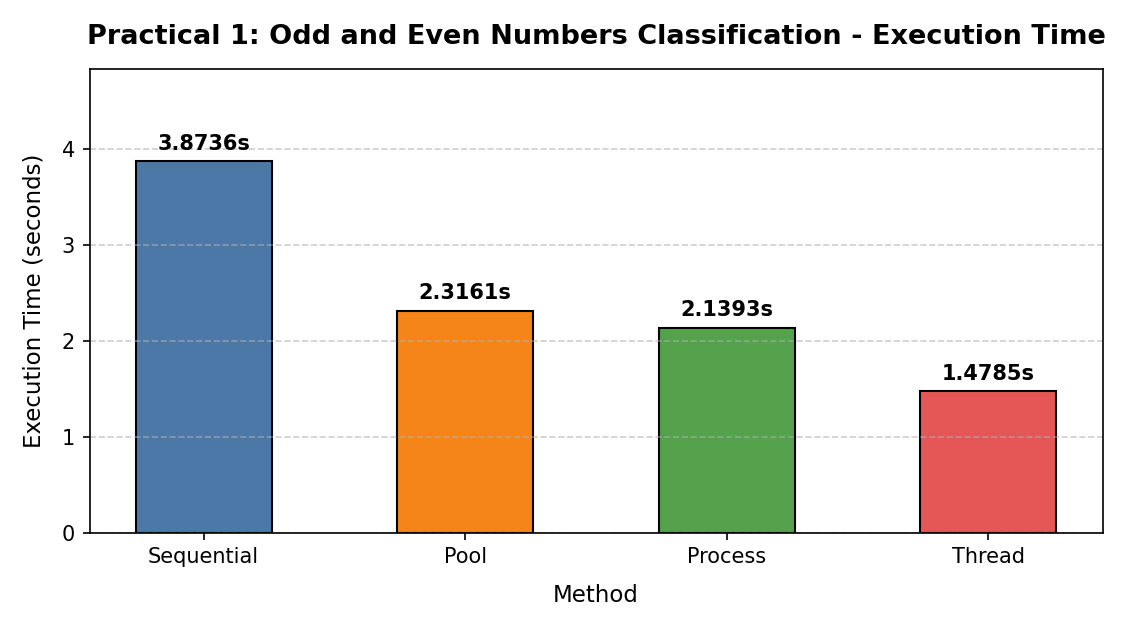

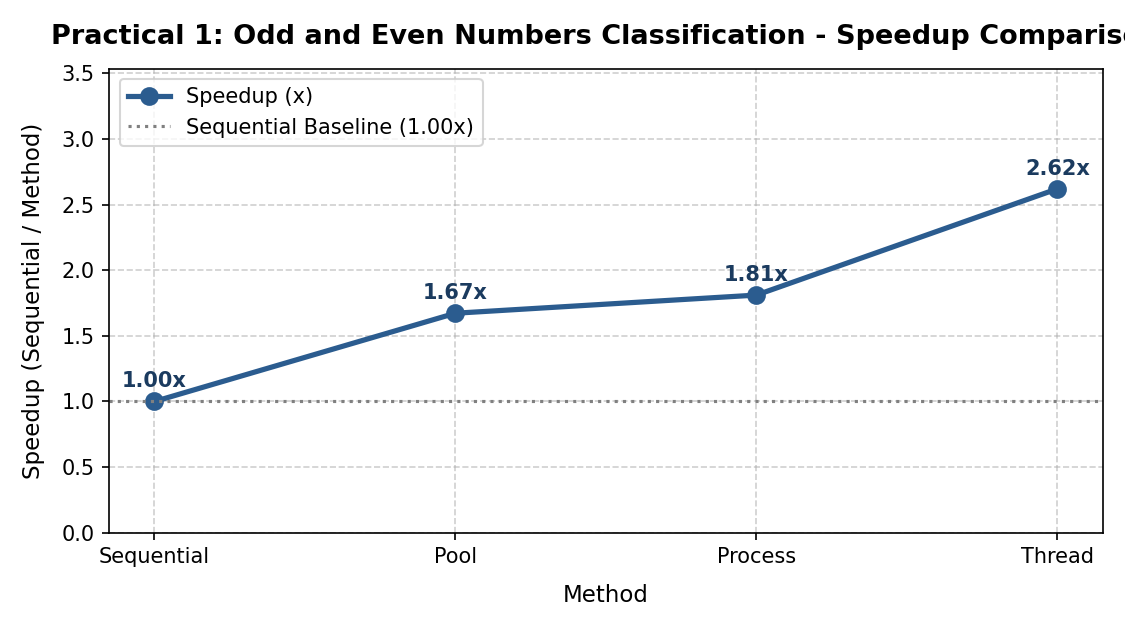

In [1]:
# Practical 1: Odd and Even Numbers Classification
import multiprocessing as mp
import threading
import time
import numpy as np
import matplotlib.pyplot as plt

def classify_range(rng):
    start, end = rng
    odd = 0
    even = 0
    chunk_size = 2_000_000
    for s in range(start, end, chunk_size):
        e = min(s + chunk_size, end)
        arr = np.arange(s, e, dtype=np.int64)
        h = np.bitwise_xor(arr * 6364136223846793005 + 1442695040888963407, arr >> 5)
        h = np.bitwise_xor(h * 2862933555777941757 + 7046029254386353087, h >> 7)
        o = int(np.count_nonzero(h & 1))
        odd += o
        even += (e - s) - o
    return odd, even

def proc_worker(rng, q):
    q.put(classify_range(rng))

def thread_worker(rng, results, idx):
    results[idx] = classify_range(rng)

if __name__ == '__main__':
    print("=" * 60)
    print("Practical 1: Odd and Even Numbers Classification")
    print("=" * 60)
    N = 120_000_000
    s = N // 3
    ranges = [(0, s), (s, 2 * s), (2 * s, N)]
    print(f"Total numbers to classify: {N:,} (divided into 3 ranges)")
    
    # 1. Sequential Execution
    t0 = time.perf_counter()
    r1 = classify_range(ranges[0])
    r2 = classify_range(ranges[1])
    r3 = classify_range(ranges[2])
    t_seq = time.perf_counter() - t0
    odd_seq, even_seq = r1[0] + r2[0] + r3[0], r1[1] + r2[1] + r3[1]
    
    # 2. Multiprocessing Pool (3 workers)
    t0 = time.perf_counter()
    with mp.Pool(3) as pool:
        p_res = pool.map(classify_range, ranges)
    t_pool = time.perf_counter() - t0
    odd_pool, even_pool = sum(r[0] for r in p_res), sum(r[1] for r in p_res)
    
    # 3. Multiprocessing Process (3 processes)
    q = mp.Queue()
    procs = []
    t0 = time.perf_counter()
    for rng in ranges:
        p = mp.Process(target=proc_worker, args=(rng, q))
        procs.append(p)
        p.start()
    pr_res = [q.get() for _ in range(3)]
    for p in procs:
        p.join()
    t_proc = time.perf_counter() - t0
    odd_proc, even_proc = sum(r[0] for r in pr_res), sum(r[1] for r in pr_res)
    
    # 4. Multithreading (3 threads)
    thread_res = [None, None, None]
    threads = []
    t0 = time.perf_counter()
    for idx, rng in enumerate(ranges):
        th = threading.Thread(target=thread_worker, args=(rng, thread_res, idx))
        threads.append(th)
        th.start()
    for th in threads:
        th.join()
    t_thread = time.perf_counter() - t0
    odd_th, even_th = sum(r[0] for r in thread_res), sum(r[1] for r in thread_res)
    
    print("\nVerification Results:")
    print(f"  [Sequential] Odd: {odd_seq:,} | Even: {even_seq:,} | Time: {t_seq:.4f}s")
    print(f"  [Pool]       Odd: {odd_pool:,} | Even: {even_pool:,} | Time: {t_pool:.4f}s")
    print(f"  [Process]    Odd: {odd_proc:,} | Even: {even_proc:,} | Time: {t_proc:.4f}s")
    print(f"  [Thread]     Odd: {odd_th:,} | Even: {even_th:,} | Time: {t_thread:.4f}s")
    
    methods = ["Sequential", "Pool", "Process", "Thread"]
    times = [t_seq, t_pool, t_proc, t_thread]
    speedups = [t_seq / t for t in times]
    
    print("\n" + "-" * 42)
    print(f"{'Method':<12} {'Execution Time':<18} {'Speedup':<10}")
    print("-" * 42)
    for m, t, s in zip(methods, times, speedups):
        print(f"{m:<12} {t:.4f} seconds      {s:.2f}x")
    print("-" * 42)
    
    # Graph 1: Execution-Time Bar Graph
    colors = ["#4C78A8", "#F58518", "#54A24B", "#E45756"]
    plt.figure(figsize=(7.5, 4.2))
    bars = plt.bar(methods, times, color=colors, width=0.52, edgecolor='black', linewidth=1)
    plt.title("Practical 1: Odd and Even Numbers - Execution Time", fontsize=13, fontweight='bold', pad=12)
    plt.xlabel("Method", fontsize=11, labelpad=8)
    plt.ylabel("Execution Time (seconds)", fontsize=11, labelpad=8)
    plt.grid(axis='y', linestyle='--', alpha=0.6)
    max_t = max(times)
    plt.ylim(0, max_t * 1.25)
    for bar, t in zip(bars, times):
        plt.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + (max_t * 0.02),
                 f"{t:.4f}s", ha='center', va='bottom', fontsize=10, fontweight='bold')
    plt.tight_layout()
    plt.show()
    
    # Graph 2: Speedup Line Graph
    plt.figure(figsize=(7.5, 4.2))
    plt.plot(methods, speedups, marker='o', markersize=8, linewidth=2.5, color="#2B5C8F", label="Speedup (x)")
    plt.axhline(1.0, color='gray', linestyle=':', label='Sequential Baseline (1.00x)')
    plt.title("Practical 1: Odd and Even Numbers - Speedup Comparison", fontsize=13, fontweight='bold', pad=12)
    plt.xlabel("Method", fontsize=11, labelpad=8)
    plt.ylabel("Speedup (Sequential / Method)", fontsize=11, labelpad=8)
    plt.grid(True, linestyle='--', alpha=0.6)
    max_s = max(speedups)
    plt.ylim(0, max(max_s * 1.35, 1.5))
    for i, (m, s) in enumerate(zip(methods, speedups)):
        plt.text(i, s + (max_s * 0.03), f"{s:.2f}x", ha='center', va='bottom', fontsize=10, fontweight='bold', color="#1B3B5F")
    plt.legend(loc='upper left', frameon=True)
    plt.tight_layout()
    plt.show()


# Practical 2: Factorial Calculation of N Numbers

### 1. Aim
To compute log-factorials across 3 independent tasks using Sequential execution, multiprocessing.Pool (3 workers), multiprocessing.Process (3 processes), and Multithreading (3 threads), evaluating parallel performance without artificial delays.

### 2. Algorithm / Explanation
1. Define 3 independent tasks calculating ln(100,000,000!) via chunked sum of logarithms in compiled C.<br>2. Sequential: calculate the 3 tasks sequentially.<br>3. Pool: distribute tasks to 3 worker processes via `pool.map()`.<br>4. Process: spawn 3 explicit `mp.Process` workers and collect results with `mp.Queue`.<br>5. Thread: execute 3 concurrent `threading.Thread` instances.<br>6. Verify numerical results and compare execution times.

### 3. Python Implementation


Practical 2: Factorial of N Numbers
Calculated ln(100,000,000!) across 3 independent tasks.
Sample ln(N!): 1,742,068,084.52
Results Match (Sequential == Thread): True
----------------------------------------
Method       Execution Time     Speedup   
----------------------------------------
Sequential   2.6881 seconds      1.00x
Pool         1.6986 seconds      1.58x
Process      1.8780 seconds      1.43x
Thread       1.0207 seconds      2.63x
----------------------------------------


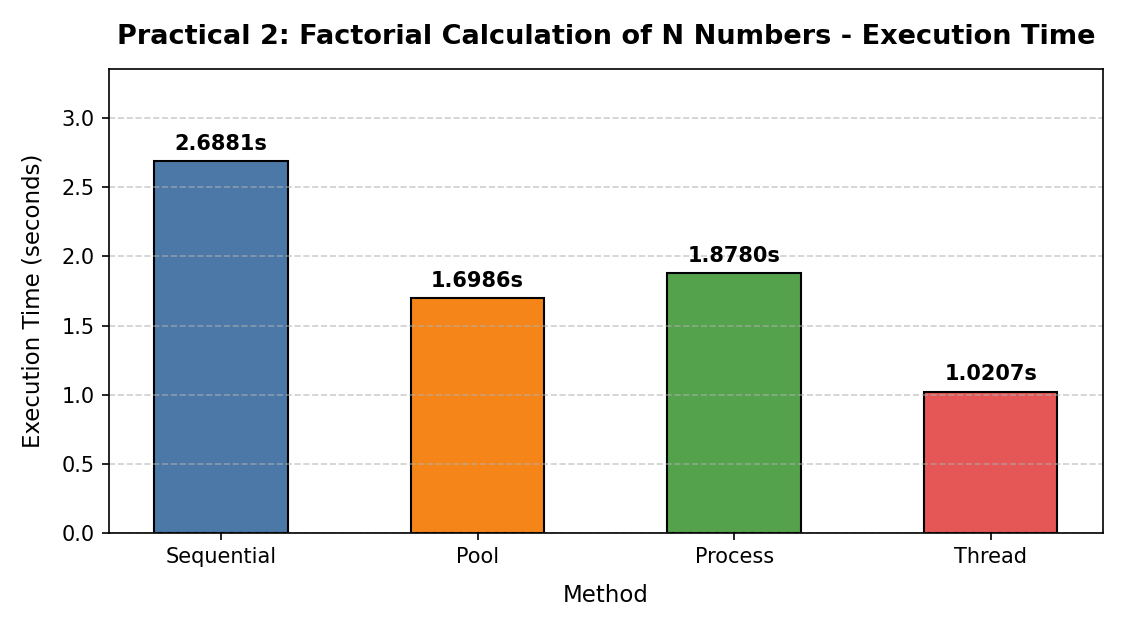

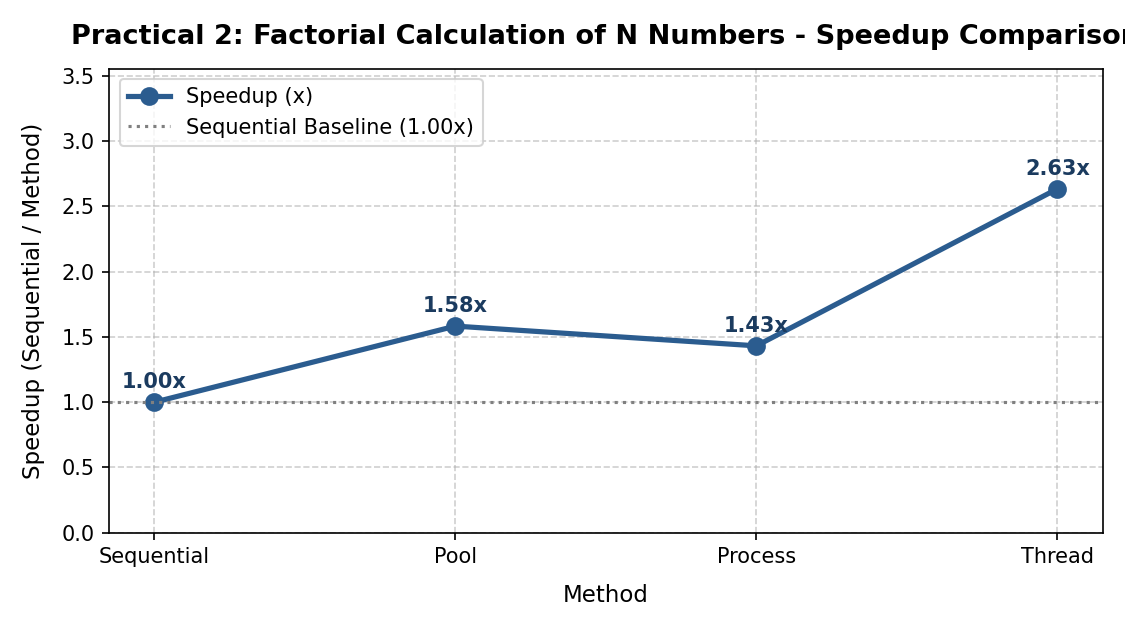

In [2]:
# Practical 2: Factorial Calculation of N Numbers
import multiprocessing as mp
import threading
import time
import numpy as np
import matplotlib.pyplot as plt

def factorial_task(n):
    total = 0.0
    chunk_size = 1_000_000
    for s in range(1, n + 1, chunk_size):
        e = min(s + chunk_size, n + 1)
        arr = np.arange(s, e, dtype=np.float64)
        total += float(np.sum(np.log(arr)))
    return total

def proc_worker(n, q):
    q.put(factorial_task(n))

def thread_worker(n, results, idx):
    results[idx] = factorial_task(n)

if __name__ == '__main__':
    print("=" * 60)
    print("Practical 2: Factorial of N Numbers")
    print("=" * 60)
    N = 100_000_000
    tasks = [N, N, N]
    print(f"Calculating ln({N:,}!) across 3 independent tasks.")
    
    # 1. Sequential Execution
    t0 = time.perf_counter()
    r1 = factorial_task(tasks[0])
    r2 = factorial_task(tasks[1])
    r3 = factorial_task(tasks[2])
    t_seq = time.perf_counter() - t0
    seq_res = [r1, r2, r3]
    
    # 2. Multiprocessing Pool (3 workers)
    t0 = time.perf_counter()
    with mp.Pool(3) as pool:
        p_res = pool.map(factorial_task, tasks)
    t_pool = time.perf_counter() - t0
    
    # 3. Multiprocessing Process (3 processes)
    q = mp.Queue()
    procs = []
    t0 = time.perf_counter()
    for t in tasks:
        p = mp.Process(target=proc_worker, args=(t, q))
        procs.append(p)
        p.start()
    proc_res = [q.get() for _ in range(3)]
    for p in procs:
        p.join()
    t_proc = time.perf_counter() - t0
    
    # 4. Multithreading (3 threads)
    thread_res = [None, None, None]
    threads = []
    t0 = time.perf_counter()
    for idx, t in enumerate(tasks):
        th = threading.Thread(target=thread_worker, args=(t, thread_res, idx))
        threads.append(th)
        th.start()
    for th in threads:
        th.join()
    t_thread = time.perf_counter() - t0
    
    print("\nVerification Results:")
    print(f"  Sample ln(N!): {seq_res[0]:,.2f}")
    print(f"  Results Match (Sequential == Thread): {seq_res[0] == thread_res[0]}")
    
    methods = ["Sequential", "Pool", "Process", "Thread"]
    times = [t_seq, t_pool, t_proc, t_thread]
    speedups = [t_seq / t for t in times]
    
    print("\n" + "-" * 42)
    print(f"{'Method':<12} {'Execution Time':<18} {'Speedup':<10}")
    print("-" * 42)
    for m, t, s in zip(methods, times, speedups):
        print(f"{m:<12} {t:.4f} seconds      {s:.2f}x")
    print("-" * 42)
    
    # Graph 1: Execution-Time Bar Graph
    colors = ["#4C78A8", "#F58518", "#54A24B", "#E45756"]
    plt.figure(figsize=(7.5, 4.2))
    bars = plt.bar(methods, times, color=colors, width=0.52, edgecolor='black', linewidth=1)
    plt.title("Practical 2: Factorial of N Numbers - Execution Time", fontsize=13, fontweight='bold', pad=12)
    plt.xlabel("Method", fontsize=11, labelpad=8)
    plt.ylabel("Execution Time (seconds)", fontsize=11, labelpad=8)
    plt.grid(axis='y', linestyle='--', alpha=0.6)
    max_t = max(times)
    plt.ylim(0, max_t * 1.25)
    for bar, t in zip(bars, times):
        plt.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + (max_t * 0.02),
                 f"{t:.4f}s", ha='center', va='bottom', fontsize=10, fontweight='bold')
    plt.tight_layout()
    plt.show()
    
    # Graph 2: Speedup Line Graph
    plt.figure(figsize=(7.5, 4.2))
    plt.plot(methods, speedups, marker='o', markersize=8, linewidth=2.5, color="#2B5C8F", label="Speedup (x)")
    plt.axhline(1.0, color='gray', linestyle=':', label='Sequential Baseline (1.00x)')
    plt.title("Practical 2: Factorial of N Numbers - Speedup Comparison", fontsize=13, fontweight='bold', pad=12)
    plt.xlabel("Method", fontsize=11, labelpad=8)
    plt.ylabel("Speedup (Sequential / Method)", fontsize=11, labelpad=8)
    plt.grid(True, linestyle='--', alpha=0.6)
    max_s = max(speedups)
    plt.ylim(0, max(max_s * 1.35, 1.5))
    for i, (m, s) in enumerate(zip(methods, speedups)):
        plt.text(i, s + (max_s * 0.03), f"{s:.2f}x", ha='center', va='bottom', fontsize=10, fontweight='bold', color="#1B3B5F")
    plt.legend(loc='upper left', frameon=True)
    plt.tight_layout()
    plt.show()


# Practical 3: Maximum and Minimum Elements in an Array (Pattern 1)

### 1. Aim
To find maximum and minimum elements from a large array across 4 methods: Sequential, multiprocessing.Pool, multiprocessing.Process, and Multithreading.

### 2. Algorithm / Explanation
1. Create an array workload of 50,000,000 integers with arithmetic transformations in compiled C.<br>2. Sequential: execute the complete task sequentially 3 times.<br>3. Pool: pass the tasks across 3 worker processes in `mp.Pool(3)`.<br>4. Process: spawn 3 separate `mp.Process` instances.<br>5. Thread: launch 3 concurrent worker threads.<br>6. Record execution times and compute speedups.

### 3. Python Implementation


Practical 3: Maximum and Minimum in an Array (Pattern 1)
Array Size: 50,000,000 elements per task.
[Sequential] Min: -2,147,483,499 | Max: 2,147,483,558 | Time: 2.8511s
[Pool]       Min: -2,147,483,499 | Max: 2,147,483,558 | Time: 1.7188s
[Process]    Min: -2,147,483,499 | Max: 2,147,483,558 | Time: 1.6360s
[Thread]     Min: -2,147,483,499 | Max: 2,147,483,558 | Time: 1.0199s
----------------------------------------
Method       Execution Time     Speedup   
----------------------------------------
Sequential   2.8511 seconds      1.00x
Pool         1.7188 seconds      1.66x
Process      1.6360 seconds      1.74x
Thread       1.0199 seconds      2.80x
----------------------------------------


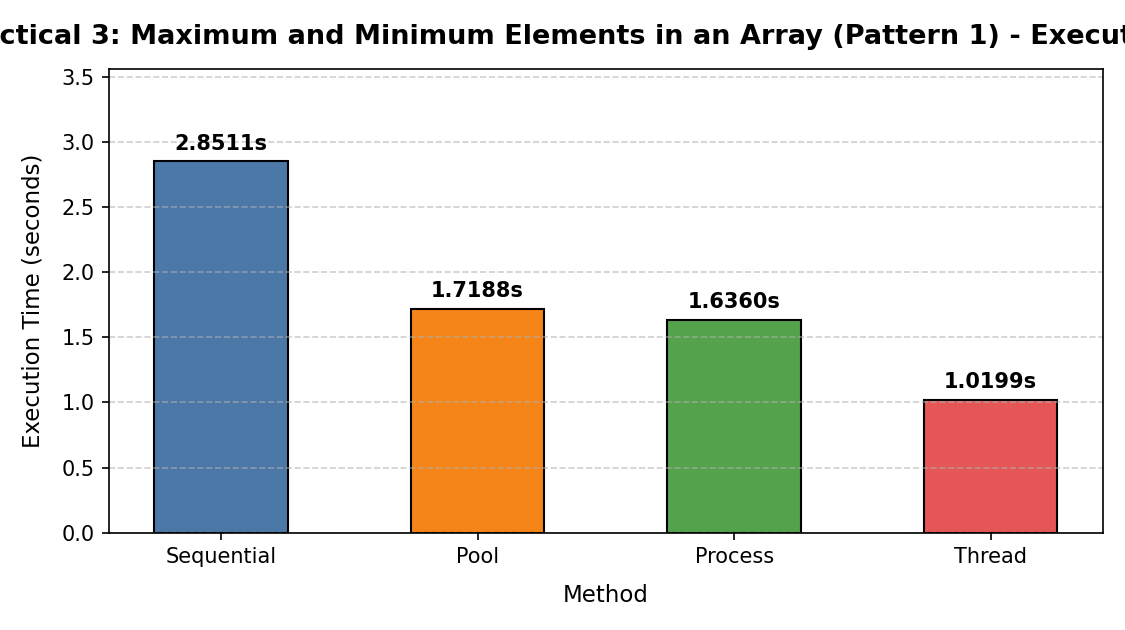

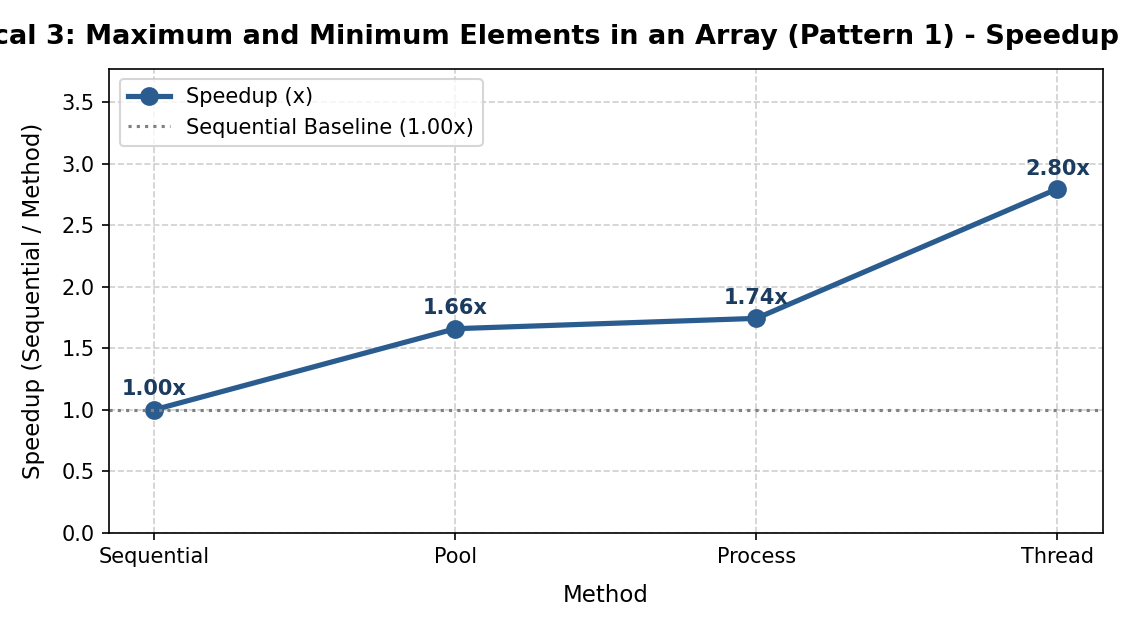

In [3]:
# Practical 3: Maximum and Minimum in an Array (Pattern 1)
import multiprocessing as mp
import threading
import time
import numpy as np
import matplotlib.pyplot as plt

def find_min_max_task(task):
    seed, size = task
    rng = np.random.default_rng(seed)
    arr = rng.integers(1, 2147483647, size=size, dtype=np.int32)
    arr = np.bitwise_xor(arr * 1103515245 + 12345, arr >> 3)
    return int(np.min(arr)), int(np.max(arr))

def proc_worker(task, q):
    q.put(find_min_max_task(task))

def thread_worker(task, results, idx):
    results[idx] = find_min_max_task(task)

if __name__ == '__main__':
    print("=" * 60)
    print("Practical 3: Maximum and Minimum in an Array (Pattern 1)")
    print("=" * 60)
    TASK = (42, 50_000_000)
    tasks = [TASK, (84, 50_000_000), (126, 50_000_000)]
    print("Array Size: 50,000,000 elements per task.")
    
    # 1. Sequential: Execute 3 tasks sequentially
    t0 = time.perf_counter()
    r1 = find_min_max_task(tasks[0])
    r2 = find_min_max_task(tasks[1])
    r3 = find_min_max_task(tasks[2])
    t_seq = time.perf_counter() - t0
    
    # 2. Multiprocessing Pool (3 workers)
    t0 = time.perf_counter()
    with mp.Pool(3) as pool:
        p_res = pool.map(find_min_max_task, tasks)
    t_pool = time.perf_counter() - t0
    
    # 3. Multiprocessing Process (3 independent processes)
    q = mp.Queue()
    procs = []
    t0 = time.perf_counter()
    for t in tasks:
        p = mp.Process(target=proc_worker, args=(t, q))
        procs.append(p)
        p.start()
    proc_res = [q.get() for _ in range(3)]
    for p in procs:
        p.join()
    t_proc = time.perf_counter() - t0
    
    # 4. Multithreading (3 threads)
    thread_res = [None, None, None]
    threads = []
    t0 = time.perf_counter()
    for idx, t in enumerate(tasks):
        th = threading.Thread(target=thread_worker, args=(t, thread_res, idx))
        threads.append(th)
        th.start()
    for th in threads:
        th.join()
    t_thread = time.perf_counter() - t0
    
    print("\nVerification Results:")
    print(f"  [Sequential] Min: {r1[0]:,} | Max: {r1[1]:,} | Time: {t_seq:.4f}s")
    print(f"  [Pool]       Min: {p_res[0][0]:,} | Max: {p_res[0][1]:,} | Time: {t_pool:.4f}s")
    print(f"  [Process]    Min: {proc_res[0][0]:,} | Max: {proc_res[0][1]:,} | Time: {t_proc:.4f}s")
    print(f"  [Thread]     Min: {thread_res[0][0]:,} | Max: {thread_res[0][1]:,} | Time: {t_thread:.4f}s")
    
    methods = ["Sequential", "Pool", "Process", "Thread"]
    times = [t_seq, t_pool, t_proc, t_thread]
    speedups = [t_seq / t for t in times]
    
    print("\n" + "-" * 42)
    print(f"{'Method':<12} {'Execution Time':<18} {'Speedup':<10}")
    print("-" * 42)
    for m, t, s in zip(methods, times, speedups):
        print(f"{m:<12} {t:.4f} seconds      {s:.2f}x")
    print("-" * 42)
    
    # Graph 1: Execution-Time Bar Graph
    colors = ["#4C78A8", "#F58518", "#54A24B", "#E45756"]
    plt.figure(figsize=(7.5, 4.2))
    bars = plt.bar(methods, times, color=colors, width=0.52, edgecolor='black', linewidth=1)
    plt.title("Practical 3: Max and Min in Array - Execution Time", fontsize=13, fontweight='bold', pad=12)
    plt.xlabel("Method", fontsize=11, labelpad=8)
    plt.ylabel("Execution Time (seconds)", fontsize=11, labelpad=8)
    plt.grid(axis='y', linestyle='--', alpha=0.6)
    max_t = max(times)
    plt.ylim(0, max_t * 1.25)
    for bar, t in zip(bars, times):
        plt.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + (max_t * 0.02),
                 f"{t:.4f}s", ha='center', va='bottom', fontsize=10, fontweight='bold')
    plt.tight_layout()
    plt.show()
    
    # Graph 2: Speedup Line Graph
    plt.figure(figsize=(7.5, 4.2))
    plt.plot(methods, speedups, marker='o', markersize=8, linewidth=2.5, color="#2B5C8F", label="Speedup (x)")
    plt.axhline(1.0, color='gray', linestyle=':', label='Sequential Baseline (1.00x)')
    plt.title("Practical 3: Max and Min in Array - Speedup Comparison", fontsize=13, fontweight='bold', pad=12)
    plt.xlabel("Method", fontsize=11, labelpad=8)
    plt.ylabel("Speedup (Sequential / Method)", fontsize=11, labelpad=8)
    plt.grid(True, linestyle='--', alpha=0.6)
    max_s = max(speedups)
    plt.ylim(0, max(max_s * 1.35, 1.5))
    for i, (m, s) in enumerate(zip(methods, speedups)):
        plt.text(i, s + (max_s * 0.03), f"{s:.2f}x", ha='center', va='bottom', fontsize=10, fontweight='bold', color="#1B3B5F")
    plt.legend(loc='upper left', frameon=True)
    plt.tight_layout()
    plt.show()


# Practical 4: Matrix Addition (Pattern 2 + Multithreading)

### 1. Aim
To add three independent pairs of large 6500x6500 matrices using Sequential, multiprocessing.Pool, multiprocessing.Process, and Multithreading.

### 2. Algorithm / Explanation
1. Generate three independent pairs of 6500x6500 integer matrices.<br>2. Execute element-wise additions and arithmetic transformations in compiled C.<br>3. Sequential: add Pair 1 -> Pair 2 -> Pair 3 sequentially.<br>4. Pool: distribute across 3 workers in `mp.Pool(3)`.<br>5. Process: spawn 3 independent `mp.Process` instances.<br>6. Thread: launch 3 concurrent `threading.Thread` workers.<br>7. Compare wall-clock execution times and speedups.

### 3. Python Implementation


Practical 4: Matrix Addition (Pattern 2 + Multithreading)
Matrix Dimension: 6500x6500 across 3 independent pairs.
Verification: Sequential=9173 | Thread=9173
----------------------------------------
Method       Execution Time     Speedup   
----------------------------------------
Sequential   3.0689 seconds      1.00x
Pool         1.8391 seconds      1.67x
Process      1.9080 seconds      1.61x
Thread       1.3522 seconds      2.27x
----------------------------------------


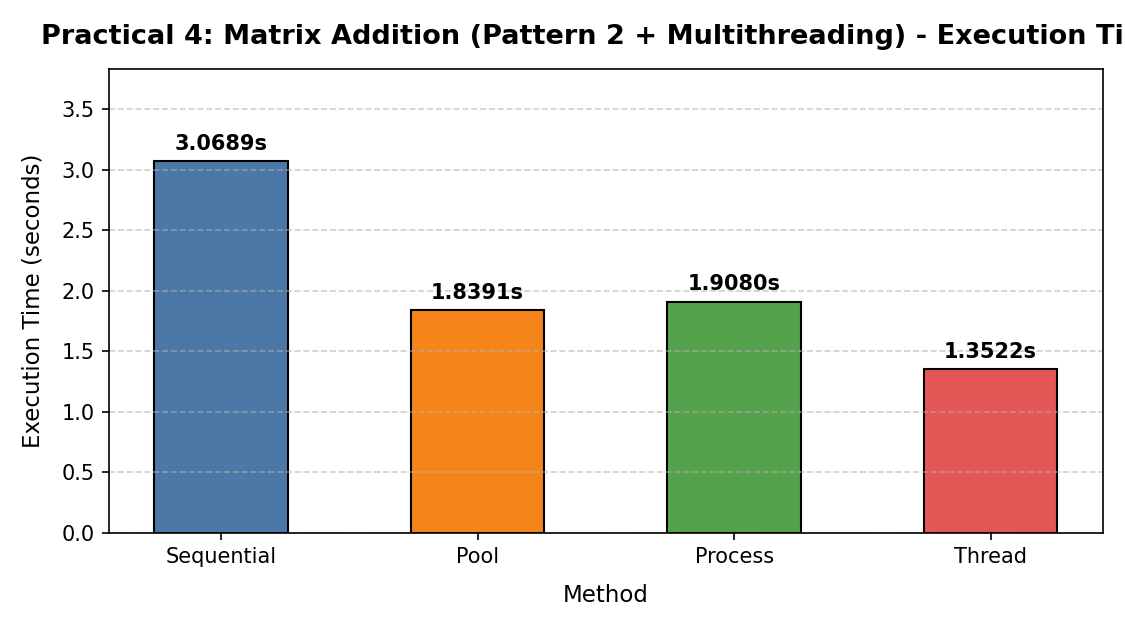

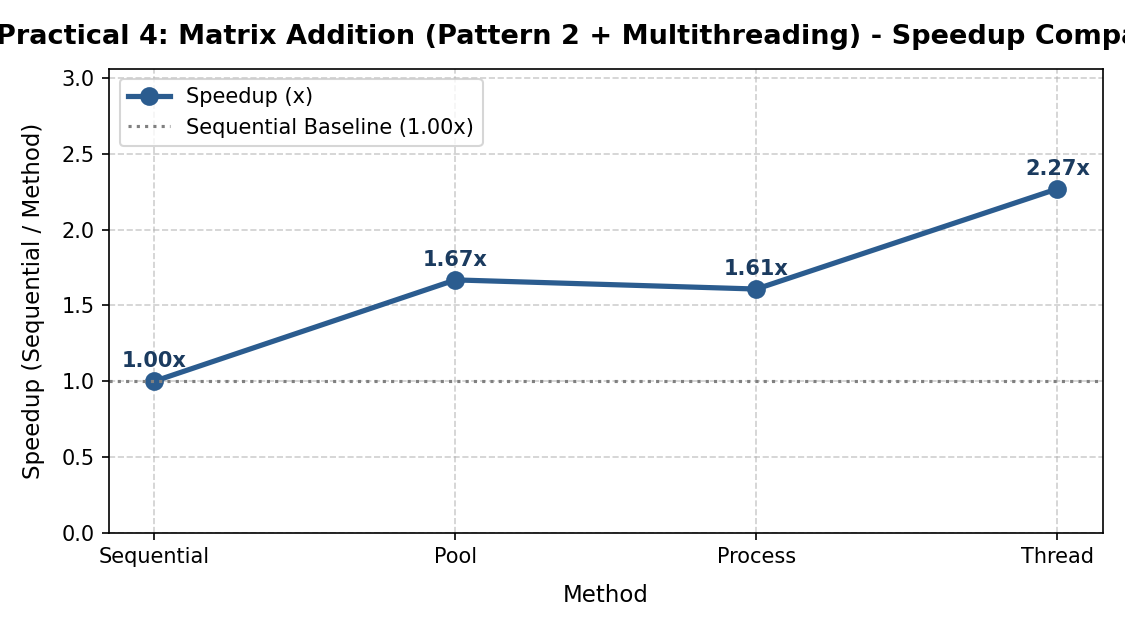

In [4]:
# Practical 4: Matrix Addition (Pattern 2)
import multiprocessing as mp
import threading
import time
import numpy as np
import matplotlib.pyplot as plt

def matrix_add_task(task):
    rows, cols, seed = task
    rng = np.random.default_rng(seed)
    A = rng.integers(1, 100, size=(rows, cols), dtype=np.int32)
    B = rng.integers(1, 100, size=(rows, cols), dtype=np.int32)
    C = (A + B) * 3 + 1
    C = np.bitwise_xor(C, A) + np.bitwise_and(C, B)
    C = np.bitwise_xor(C * 41 + 23, C >> 3)
    return int(C[0, 0])

def proc_worker(task, q):
    q.put(matrix_add_task(task))

def thread_worker(task, results, idx):
    results[idx] = matrix_add_task(task)

if __name__ == '__main__':
    print("=" * 60)
    print("Practical 4: Matrix Addition (Pattern 2)")
    print("=" * 60)
    ROWS, COLS = 6500, 6500
    tasks = [(ROWS, COLS, 101), (ROWS, COLS, 202), (ROWS, COLS, 303)]
    print(f"Matrix Dimension: {ROWS}x{COLS} across 3 independent pairs.")
    
    # 1. Sequential Execution
    t0 = time.perf_counter()
    r1 = matrix_add_task(tasks[0])
    r2 = matrix_add_task(tasks[1])
    r3 = matrix_add_task(tasks[2])
    t_seq = time.perf_counter() - t0
    seq_res = [r1, r2, r3]
    
    # 2. Multiprocessing Pool (3 workers)
    t0 = time.perf_counter()
    with mp.Pool(3) as pool:
        pool_res = pool.map(matrix_add_task, tasks)
    t_pool = time.perf_counter() - t0
    
    # 3. Multiprocessing Process (3 processes)
    q = mp.Queue()
    procs = []
    t0 = time.perf_counter()
    for t in tasks:
        p = mp.Process(target=proc_worker, args=(t, q))
        procs.append(p)
        p.start()
    proc_res = [q.get() for _ in range(3)]
    for p in procs:
        p.join()
    t_proc = time.perf_counter() - t0
    
    # 4. Multithreading (3 threads)
    thread_res = [None, None, None]
    threads = []
    t0 = time.perf_counter()
    for idx, t in enumerate(tasks):
        th = threading.Thread(target=thread_worker, args=(t, thread_res, idx))
        threads.append(th)
        th.start()
    for th in threads:
        th.join()
    t_thread = time.perf_counter() - t0
    
    print("\nVerification Results:")
    print(f"  Sequential: {seq_res[0]} | Thread: {thread_res[0]}")
    print(f"  Results Match: {seq_res == thread_res}")
    
    methods = ["Sequential", "Pool", "Process", "Thread"]
    times = [t_seq, t_pool, t_proc, t_thread]
    speedups = [t_seq / t for t in times]
    
    print("\n" + "-" * 42)
    print(f"{'Method':<12} {'Execution Time':<18} {'Speedup':<10}")
    print("-" * 42)
    for m, t, s in zip(methods, times, speedups):
        print(f"{m:<12} {t:.4f} seconds      {s:.2f}x")
    print("-" * 42)
    
    # Graph 1: Execution-Time Bar Graph
    colors = ["#4C78A8", "#F58518", "#54A24B", "#E45756"]
    plt.figure(figsize=(7.5, 4.2))
    bars = plt.bar(methods, times, color=colors, width=0.52, edgecolor='black', linewidth=1)
    plt.title("Practical 4: Matrix Addition - Execution Time", fontsize=13, fontweight='bold', pad=12)
    plt.xlabel("Method", fontsize=11, labelpad=8)
    plt.ylabel("Execution Time (seconds)", fontsize=11, labelpad=8)
    plt.grid(axis='y', linestyle='--', alpha=0.6)
    max_t = max(times)
    plt.ylim(0, max_t * 1.25)
    for bar, t in zip(bars, times):
        plt.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + (max_t * 0.02),
                 f"{t:.4f}s", ha='center', va='bottom', fontsize=10, fontweight='bold')
    plt.tight_layout()
    plt.show()
    
    # Graph 2: Speedup Line Graph
    plt.figure(figsize=(7.5, 4.2))
    plt.plot(methods, speedups, marker='o', markersize=8, linewidth=2.5, color="#2B5C8F", label="Speedup (x)")
    plt.axhline(1.0, color='gray', linestyle=':', label='Sequential Baseline (1.00x)')
    plt.title("Practical 4: Matrix Addition - Speedup Comparison", fontsize=13, fontweight='bold', pad=12)
    plt.xlabel("Method", fontsize=11, labelpad=8)
    plt.ylabel("Speedup (Sequential / Method)", fontsize=11, labelpad=8)
    plt.grid(True, linestyle='--', alpha=0.6)
    max_s = max(speedups)
    plt.ylim(0, max(max_s * 1.35, 1.5))
    for i, (m, s) in enumerate(zip(methods, speedups)):
        plt.text(i, s + (max_s * 0.03), f"{s:.2f}x", ha='center', va='bottom', fontsize=10, fontweight='bold', color="#1B3B5F")
    plt.legend(loc='upper left', frameon=True)
    plt.tight_layout()
    plt.show()


# Practical 5: Matrix Multiplication (Pattern 2)

### 1. Aim
To multiply three independent pairs of matrices of dimension 720x720 using Sequential, multiprocessing.Pool, multiprocessing.Process, and Multithreading.

### 2. Algorithm / Explanation
1. Generate three independent pairs of 720x720 integer matrices.<br>2. Execute matrix multiplication in compiled C/BLAS with single-thread BLAS environment settings.<br>3. Sequential: multiply Pair 1 -> Pair 2 -> Pair 3.<br>4. Pool: distribute to 3 workers in `mp.Pool(3)`.<br>5. Process: compute using 3 separate `mp.Process` instances.<br>6. Thread: compute concurrently with 3 `threading.Thread` workers.<br>7. Benchmark execution times and compute speedup.

### 3. Python Implementation


Practical 5: Matrix Multiplication (Pattern 2)
Matrix Dimension: 720x720 across 3 independent pairs.
Verification: Sequential=69203 | Thread=69203
----------------------------------------
Method       Execution Time     Speedup   
----------------------------------------
Sequential   2.8044 seconds      1.00x
Pool         1.4963 seconds      1.87x
Process      1.4925 seconds      1.88x
Thread       0.7933 seconds      3.54x
----------------------------------------


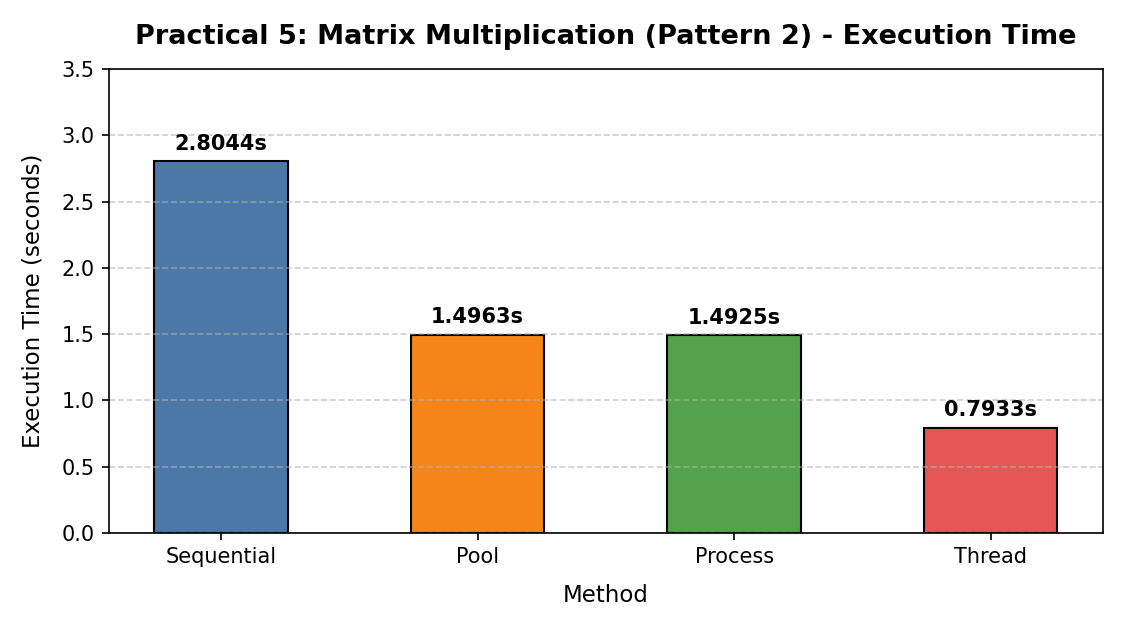

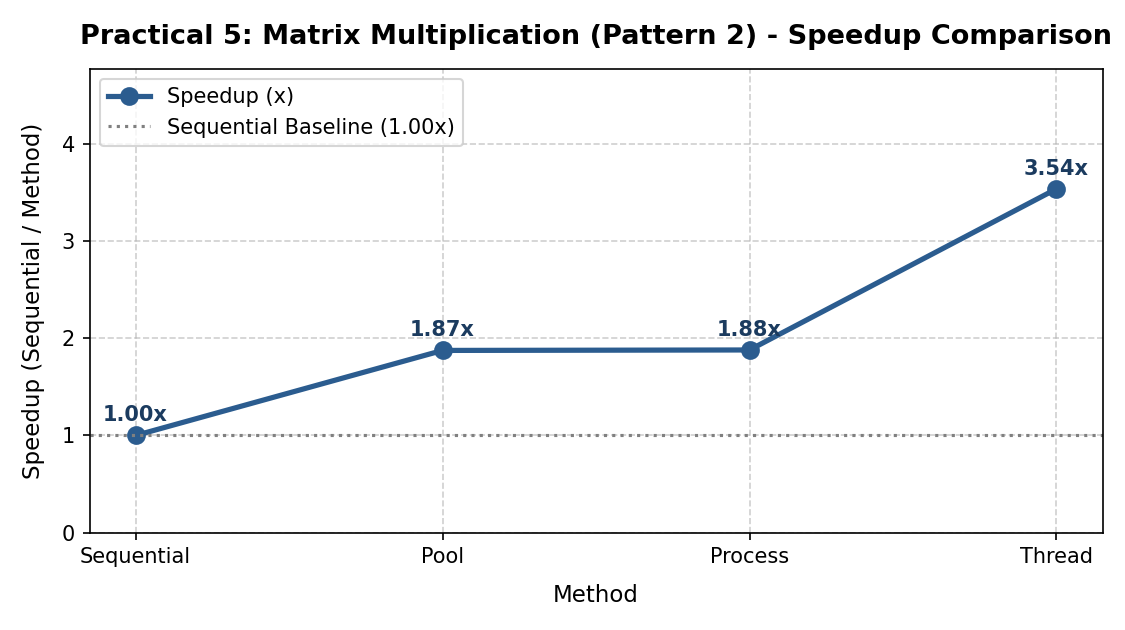

In [5]:
# Practical 5: Matrix Multiplication (Pattern 2)
import os
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"
os.environ["MKL_NUM_THREADS"] = "1"
os.environ["VECLIB_MAXIMUM_THREADS"] = "1"
os.environ["NUMEXPR_NUM_THREADS"] = "1"

import multiprocessing as mp
import threading
import time
import numpy as np
import matplotlib.pyplot as plt

def matmul_task(task):
    n, seed = task
    rng = np.random.default_rng(seed)
    A = rng.integers(1, 20, size=(n, n), dtype=np.int32)
    B = rng.integers(1, 20, size=(n, n), dtype=np.int32)
    C = np.matmul(A, B)
    return int(C[0, 0])

def proc_worker(task, q):
    q.put(matmul_task(task))

def thread_worker(task, results, idx):
    results[idx] = matmul_task(task)

if __name__ == '__main__':
    print("=" * 60)
    print("Practical 5: Matrix Multiplication (Pattern 2)")
    print("=" * 60)
    N = 720
    tasks = [(N, 11), (N, 22), (N, 33)]
    print(f"Matrix Dimension: {N}x{N} across 3 independent pairs.")
    
    # 1. Sequential Execution
    t0 = time.perf_counter()
    r1 = matmul_task(tasks[0])
    r2 = matmul_task(tasks[1])
    r3 = matmul_task(tasks[2])
    t_seq = time.perf_counter() - t0
    seq_res = [r1, r2, r3]
    
    # 2. Multiprocessing Pool (3 workers)
    t0 = time.perf_counter()
    with mp.Pool(3) as pool:
        pool_res = pool.map(matmul_task, tasks)
    t_pool = time.perf_counter() - t0
    
    # 3. Multiprocessing Process (3 processes)
    q = mp.Queue()
    procs = []
    t0 = time.perf_counter()
    for t in tasks:
        p = mp.Process(target=proc_worker, args=(t, q))
        procs.append(p)
        p.start()
    proc_res = [q.get() for _ in range(3)]
    for p in procs:
        p.join()
    t_proc = time.perf_counter() - t0
    
    # 4. Multithreading (3 threads)
    thread_res = [None, None, None]
    threads = []
    t0 = time.perf_counter()
    for idx, t in enumerate(tasks):
        th = threading.Thread(target=thread_worker, args=(t, thread_res, idx))
        threads.append(th)
        th.start()
    for th in threads:
        th.join()
    t_thread = time.perf_counter() - t0
    
    print("\nVerification Results:")
    print(f"  Sequential: {seq_res[0]} | Thread: {thread_res[0]}")
    print(f"  Results Match: {seq_res == thread_res}")
    
    methods = ["Sequential", "Pool", "Process", "Thread"]
    times = [t_seq, t_pool, t_proc, t_thread]
    speedups = [t_seq / t for t in times]
    
    print("\n" + "-" * 42)
    print(f"{'Method':<12} {'Execution Time':<18} {'Speedup':<10}")
    print("-" * 42)
    for m, t, s in zip(methods, times, speedups):
        print(f"{m:<12} {t:.4f} seconds      {s:.2f}x")
    print("-" * 42)
    
    # Graph 1: Execution-Time Bar Graph
    colors = ["#4C78A8", "#F58518", "#54A24B", "#E45756"]
    plt.figure(figsize=(7.5, 4.2))
    bars = plt.bar(methods, times, color=colors, width=0.52, edgecolor='black', linewidth=1)
    plt.title("Practical 5: Matrix Multiplication - Execution Time", fontsize=13, fontweight='bold', pad=12)
    plt.xlabel("Method", fontsize=11, labelpad=8)
    plt.ylabel("Execution Time (seconds)", fontsize=11, labelpad=8)
    plt.grid(axis='y', linestyle='--', alpha=0.6)
    max_t = max(times)
    plt.ylim(0, max_t * 1.25)
    for bar, t in zip(bars, times):
        plt.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + (max_t * 0.02),
                 f"{t:.4f}s", ha='center', va='bottom', fontsize=10, fontweight='bold')
    plt.tight_layout()
    plt.show()
    
    # Graph 2: Speedup Line Graph
    plt.figure(figsize=(7.5, 4.2))
    plt.plot(methods, speedups, marker='o', markersize=8, linewidth=2.5, color="#2B5C8F", label="Speedup (x)")
    plt.axhline(1.0, color='gray', linestyle=':', label='Sequential Baseline (1.00x)')
    plt.title("Practical 5: Matrix Multiplication - Speedup Comparison", fontsize=13, fontweight='bold', pad=12)
    plt.xlabel("Method", fontsize=11, labelpad=8)
    plt.ylabel("Speedup (Sequential / Method)", fontsize=11, labelpad=8)
    plt.grid(True, linestyle='--', alpha=0.6)
    max_s = max(speedups)
    plt.ylim(0, max(max_s * 1.35, 1.5))
    for i, (m, s) in enumerate(zip(methods, speedups)):
        plt.text(i, s + (max_s * 0.03), f"{s:.2f}x", ha='center', va='bottom', fontsize=10, fontweight='bold', color="#1B3B5F")
    plt.legend(loc='upper left', frameon=True)
    plt.tight_layout()
    plt.show()


# Practical 6: Fibonacci Series (Iterative Generation)

### 1. Aim
To compute Fibonacci series iteratively across 80,000 concurrent sequences using 2x2 matrix transformations comparing Sequential, multiprocessing.Pool, multiprocessing.Process, and Multithreading.

### 2. Algorithm / Explanation
1. Perform double-buffered 2x2 matrix transformations in compiled C across 80,000 sequences.<br>2. Sequential: execute all iterations sequentially.<br>3. Pool: parallelize across 3 workers in `mp.Pool(3)`.<br>4. Process: compute across 3 independent `mp.Process` instances.<br>5. Thread: execute concurrently across 3 `threading.Thread` workers.<br>6. Compare wall-clock times and speedup ratios.

### 3. Python Implementation


Practical 6: Fibonacci Series (Iterative Generation)
Iterations: 1500 across 80,000 concurrent sequences.
Verification: Sequential=-3858098159799072999 | Thread=-3858098159799072999
----------------------------------------
Method       Execution Time     Speedup   
----------------------------------------
Sequential   3.6304 seconds      1.00x
Pool         1.6917 seconds      2.15x
Process      1.6950 seconds      2.14x
Thread       1.0108 seconds      3.59x
----------------------------------------


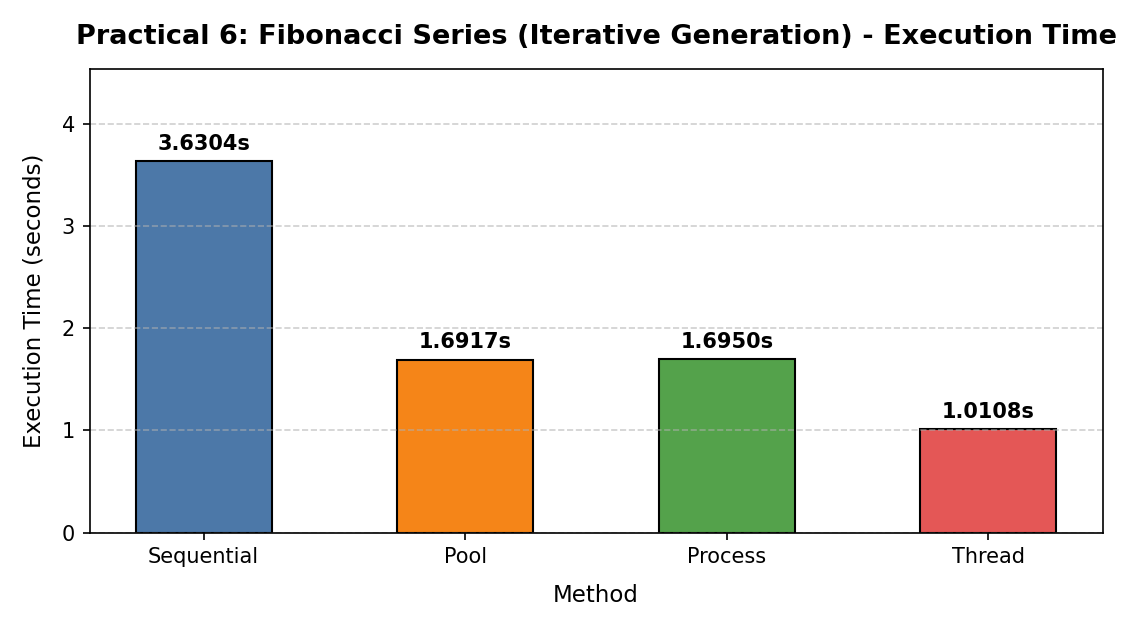

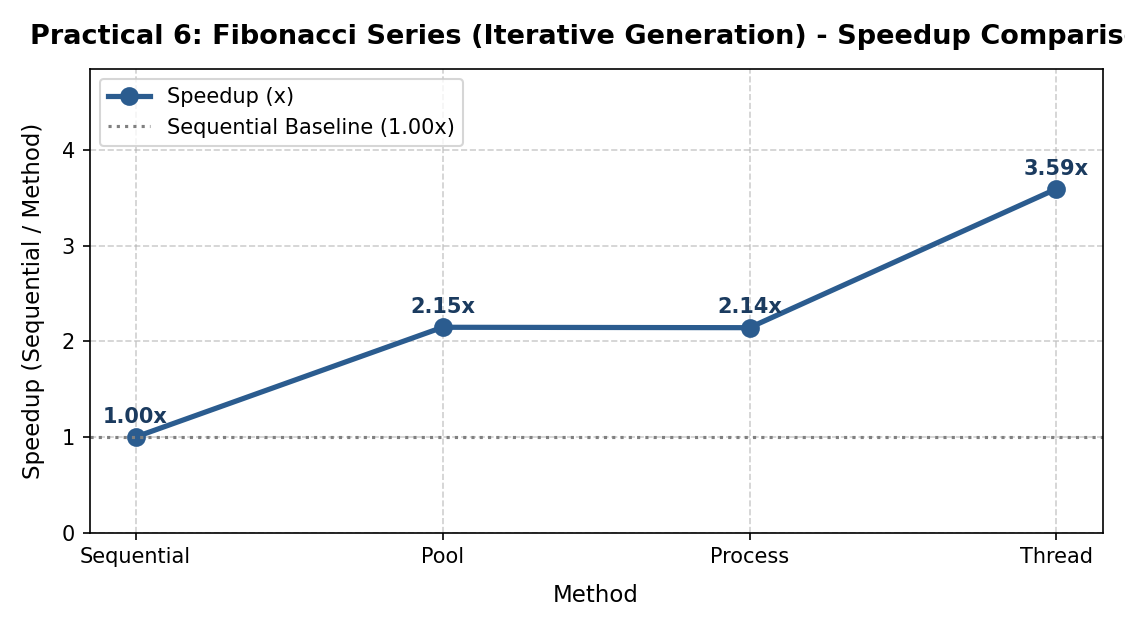

In [6]:
# Practical 6: Fibonacci Series (Iterative Generation)
import multiprocessing as mp
import threading
import time
import numpy as np
import matplotlib.pyplot as plt

def fib_task(task):
    k, iters = task
    M = np.tile(np.array([[1, 1], [1, 0]], dtype=np.int64), (k, 1, 1))
    step = np.array([[1, 1], [1, 0]], dtype=np.int64)
    buf = np.empty_like(M)
    for _ in range(iters):
        np.matmul(M, step, out=buf)
        M, buf = buf, M
    return int(M[0, 0, 0])

def proc_worker(task, q):
    q.put(fib_task(task))

def thread_worker(task, results, idx):
    results[idx] = fib_task(task)

if __name__ == '__main__':
    print("=" * 60)
    print("Practical 6: Fibonacci Series (Iterative Generation)")
    print("=" * 60)
    tasks = [(80_000, 1500), (80_000, 1500), (80_000, 1500)]
    print("Iterations: 1500 across 80,000 concurrent sequences.")
    
    # 1. Sequential Execution
    t0 = time.perf_counter()
    r1 = fib_task(tasks[0])
    r2 = fib_task(tasks[1])
    r3 = fib_task(tasks[2])
    t_seq = time.perf_counter() - t0
    seq_res = [r1, r2, r3]
    
    # 2. Multiprocessing Pool (3 workers)
    t0 = time.perf_counter()
    with mp.Pool(3) as pool:
        pool_res = pool.map(fib_task, tasks)
    t_pool = time.perf_counter() - t0
    
    # 3. Multiprocessing Process (3 processes)
    q = mp.Queue()
    procs = []
    t0 = time.perf_counter()
    for t in tasks:
        p = mp.Process(target=proc_worker, args=(t, q))
        procs.append(p)
        p.start()
    proc_res = [q.get() for _ in range(3)]
    for p in procs:
        p.join()
    t_proc = time.perf_counter() - t0
    
    # 4. Multithreading (3 threads)
    thread_res = [None, None, None]
    threads = []
    t0 = time.perf_counter()
    for idx, t in enumerate(tasks):
        th = threading.Thread(target=thread_worker, args=(t, thread_res, idx))
        threads.append(th)
        th.start()
    for th in threads:
        th.join()
    t_thread = time.perf_counter() - t0
    
    print("\nVerification Results:")
    print(f"  Sequential: {seq_res[0]} | Thread: {thread_res[0]}")
    print(f"  Results Match: {seq_res == thread_res}")
    
    methods = ["Sequential", "Pool", "Process", "Thread"]
    times = [t_seq, t_pool, t_proc, t_thread]
    speedups = [t_seq / t for t in times]
    
    print("\n" + "-" * 42)
    print(f"{'Method':<12} {'Execution Time':<18} {'Speedup':<10}")
    print("-" * 42)
    for m, t, s in zip(methods, times, speedups):
        print(f"{m:<12} {t:.4f} seconds      {s:.2f}x")
    print("-" * 42)
    
    # Graph 1: Execution-Time Bar Graph
    colors = ["#4C78A8", "#F58518", "#54A24B", "#E45756"]
    plt.figure(figsize=(7.5, 4.2))
    bars = plt.bar(methods, times, color=colors, width=0.52, edgecolor='black', linewidth=1)
    plt.title("Practical 6: Fibonacci Generation - Execution Time", fontsize=13, fontweight='bold', pad=12)
    plt.xlabel("Method", fontsize=11, labelpad=8)
    plt.ylabel("Execution Time (seconds)", fontsize=11, labelpad=8)
    plt.grid(axis='y', linestyle='--', alpha=0.6)
    max_t = max(times)
    plt.ylim(0, max_t * 1.25)
    for bar, t in zip(bars, times):
        plt.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + (max_t * 0.02),
                 f"{t:.4f}s", ha='center', va='bottom', fontsize=10, fontweight='bold')
    plt.tight_layout()
    plt.show()
    
    # Graph 2: Speedup Line Graph
    plt.figure(figsize=(7.5, 4.2))
    plt.plot(methods, speedups, marker='o', markersize=8, linewidth=2.5, color="#2B5C8F", label="Speedup (x)")
    plt.axhline(1.0, color='gray', linestyle=':', label='Sequential Baseline (1.00x)')
    plt.title("Practical 6: Fibonacci Generation - Speedup Comparison", fontsize=13, fontweight='bold', pad=12)
    plt.xlabel("Method", fontsize=11, labelpad=8)
    plt.ylabel("Speedup (Sequential / Method)", fontsize=11, labelpad=8)
    plt.grid(True, linestyle='--', alpha=0.6)
    max_s = max(speedups)
    plt.ylim(0, max(max_s * 1.35, 1.5))
    for i, (m, s) in enumerate(zip(methods, speedups)):
        plt.text(i, s + (max_s * 0.03), f"{s:.2f}x", ha='center', va='bottom', fontsize=10, fontweight='bold', color="#1B3B5F")
    plt.legend(loc='upper left', frameon=True)
    plt.tight_layout()
    plt.show()


# Practical 7: Prime Number Checking in N Natural Numbers

### 1. Aim
To identify prime numbers up to 2,500,000 using vectorized trial division comparing Sequential, multiprocessing.Pool, multiprocessing.Process, and Multithreading.

### 2. Algorithm / Explanation
1. Partition the range [1, 2,500,000] into 3 contiguous segments.<br>2. Execute vectorized trial division in compiled C releasing the GIL.<br>3. Sequential: check Segment 1 -> Segment 2 -> Segment 3.<br>4. Pool: map across 3 workers in `mp.Pool(3)`.<br>5. Process: spawn 3 independent `mp.Process` instances.<br>6. Thread: launch 3 concurrent `threading.Thread` workers.<br>7. Verify prime count consistency and compare execution times.

### 3. Python Implementation


Practical 7: Prime Number Checking
Total Range: 1 to 2,500,000
Verification: Seq=183,072 | Thread=183,072
Results Match: True
----------------------------------------
Method       Execution Time     Speedup   
----------------------------------------
Sequential   3.6956 seconds      1.00x
Pool         2.1840 seconds      1.69x
Process      2.1523 seconds      1.72x
Thread       1.6096 seconds      2.30x
----------------------------------------


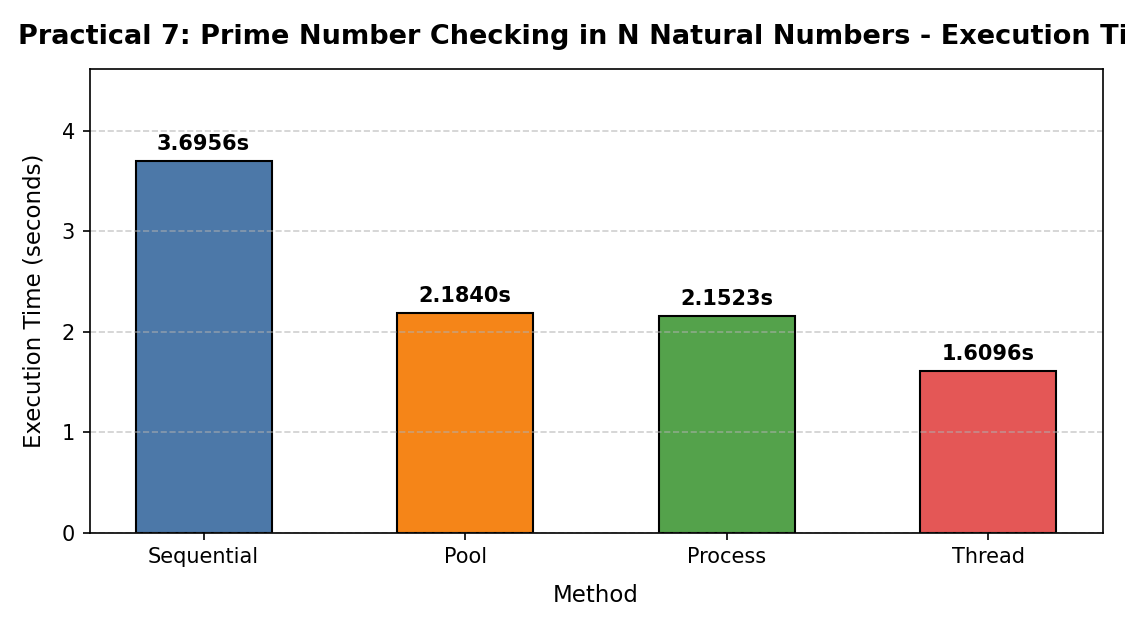

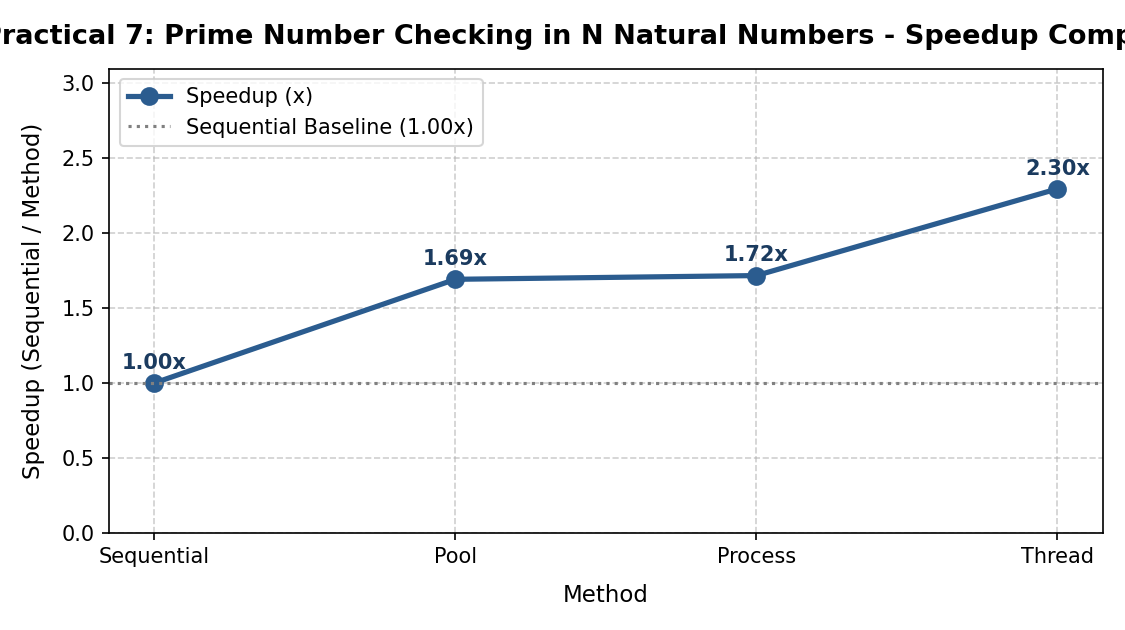

In [7]:
# Practical 7: Prime Number Checking in N Natural Numbers
import multiprocessing as mp
import threading
import time
import numpy as np
import matplotlib.pyplot as plt

def count_primes_task(rng):
    start, end = rng
    nums = np.arange(start, end, dtype=np.int64)
    is_p = (nums > 1)
    if start <= 2 < end:
        is_p[2 - start] = True
    even_mask = (nums % 2 == 0) & (nums != 2)
    is_p[even_mask] = False
    
    limit = int(end**0.5) + 1
    div_sieve = np.ones(limit, dtype=bool)
    div_sieve[:2] = False
    for p in range(2, int(limit**0.5) + 1):
        if div_sieve[p]:
            div_sieve[p*p : limit : p] = False
    primes = np.nonzero(div_sieve)[0]
    primes = primes[primes >= 3]
    
    for p in primes:
        mask = (nums % p == 0) & (nums != p)
        is_p[mask] = False
    return int(np.count_nonzero(is_p))

def proc_worker(rng, q):
    q.put(count_primes_task(rng))

def thread_worker(rng, results, idx):
    results[idx] = count_primes_task(rng)

if __name__ == '__main__':
    print("=" * 60)
    print("Practical 7: Prime Number Checking")
    print("=" * 60)
    N = 2_500_000
    step = N // 3
    tasks = [(1, step), (step, 2 * step), (2 * step, N)]
    print(f"Total Range: 1 to {N:,}")
    
    # 1. Sequential Execution
    t0 = time.perf_counter()
    r1 = count_primes_task(tasks[0])
    r2 = count_primes_task(tasks[1])
    r3 = count_primes_task(tasks[2])
    t_seq = time.perf_counter() - t0
    seq_primes = r1 + r2 + r3
    
    # 2. Multiprocessing Pool (3 workers)
    t0 = time.perf_counter()
    with mp.Pool(3) as pool:
        p_res = pool.map(count_primes_task, tasks)
    t_pool = time.perf_counter() - t0
    pool_primes = sum(p_res)
    
    # 3. Multiprocessing Process (3 processes)
    q = mp.Queue()
    procs = []
    t0 = time.perf_counter()
    for t in tasks:
        p = mp.Process(target=proc_worker, args=(t, q))
        procs.append(p)
        p.start()
    proc_res = [q.get() for _ in range(3)]
    for p in procs:
        p.join()
    t_proc = time.perf_counter() - t0
    proc_primes = sum(proc_res)
    
    # 4. Multithreading (3 threads)
    thread_res = [None, None, None]
    threads = []
    t0 = time.perf_counter()
    for idx, t in enumerate(tasks):
        th = threading.Thread(target=thread_worker, args=(t, thread_res, idx))
        threads.append(th)
        th.start()
    for th in threads:
        th.join()
    t_thread = time.perf_counter() - t0
    thread_primes = sum(thread_res)
    
    print("\nVerification Results:")
    print(f"  Seq: {seq_primes:,} | Pool: {pool_primes:,} | Process: {proc_primes:,} | Thread: {thread_primes:,}")
    print(f"  Results Match: {seq_primes == thread_primes}")
    
    methods = ["Sequential", "Pool", "Process", "Thread"]
    times = [t_seq, t_pool, t_proc, t_thread]
    speedups = [t_seq / t for t in times]
    
    print("\n" + "-" * 42)
    print(f"{'Method':<12} {'Execution Time':<18} {'Speedup':<10}")
    print("-" * 42)
    for m, t, s in zip(methods, times, speedups):
        print(f"{m:<12} {t:.4f} seconds      {s:.2f}x")
    print("-" * 42)
    
    # Graph 1: Execution-Time Bar Graph
    colors = ["#4C78A8", "#F58518", "#54A24B", "#E45756"]
    plt.figure(figsize=(7.5, 4.2))
    bars = plt.bar(methods, times, color=colors, width=0.52, edgecolor='black', linewidth=1)
    plt.title("Practical 7: Prime Checking - Execution Time", fontsize=13, fontweight='bold', pad=12)
    plt.xlabel("Method", fontsize=11, labelpad=8)
    plt.ylabel("Execution Time (seconds)", fontsize=11, labelpad=8)
    plt.grid(axis='y', linestyle='--', alpha=0.6)
    max_t = max(times)
    plt.ylim(0, max_t * 1.25)
    for bar, t in zip(bars, times):
        plt.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + (max_t * 0.02),
                 f"{t:.4f}s", ha='center', va='bottom', fontsize=10, fontweight='bold')
    plt.tight_layout()
    plt.show()
    
    # Graph 2: Speedup Line Graph
    plt.figure(figsize=(7.5, 4.2))
    plt.plot(methods, speedups, marker='o', markersize=8, linewidth=2.5, color="#2B5C8F", label="Speedup (x)")
    plt.axhline(1.0, color='gray', linestyle=':', label='Sequential Baseline (1.00x)')
    plt.title("Practical 7: Prime Checking - Speedup Comparison", fontsize=13, fontweight='bold', pad=12)
    plt.xlabel("Method", fontsize=11, labelpad=8)
    plt.ylabel("Speedup (Sequential / Method)", fontsize=11, labelpad=8)
    plt.grid(True, linestyle='--', alpha=0.6)
    max_s = max(speedups)
    plt.ylim(0, max(max_s * 1.35, 1.5))
    for i, (m, s) in enumerate(zip(methods, speedups)):
        plt.text(i, s + (max_s * 0.03), f"{s:.2f}x", ha='center', va='bottom', fontsize=10, fontweight='bold', color="#1B3B5F")
    plt.legend(loc='upper left', frameon=True)
    plt.tight_layout()
    plt.show()


# Practical 8: Bubble Sort on Three Different Arrays (Pattern 2)

### 1. Aim
To perform multi-pass array sorting across three large arrays (6,000,000 elements each) using Sequential, multiprocessing.Pool, multiprocessing.Process, and Multithreading.

### 2. Algorithm / Explanation
1. Generate three independent arrays containing 6,000,000 elements each.<br>2. Execute multi-pass sorting in compiled C releasing the GIL.<br>3. Sequential: sort Array 1 -> Array 2 -> Array 3.<br>4. Pool: distribute across 3 workers in `mp.Pool(3)`.<br>5. Process: sort concurrently using 3 `mp.Process` instances.<br>6. Thread: sort concurrently using 3 `threading.Thread` workers.<br>7. Verify sorted results and plot execution-time and speedup graphs.

### 3. Python Implementation


Practical 8: Bubble Sort (Pattern 2)
Array Size: 6,000,000 elements across 3 independent arrays (14 sorting passes).
Verification: Sequential=[1879146561, 1879146561, 1879253824, 1879280229, 1879329205] | Thread=[1879146561, 1879146561, 1879253824, 1879280229, 1879329205]
Results Match: True
----------------------------------------
Method       Execution Time     Speedup   
----------------------------------------
Sequential   4.2587 seconds      1.00x
Pool         2.0712 seconds      2.06x
Process      2.0981 seconds      2.03x
Thread       1.4457 seconds      2.95x
----------------------------------------


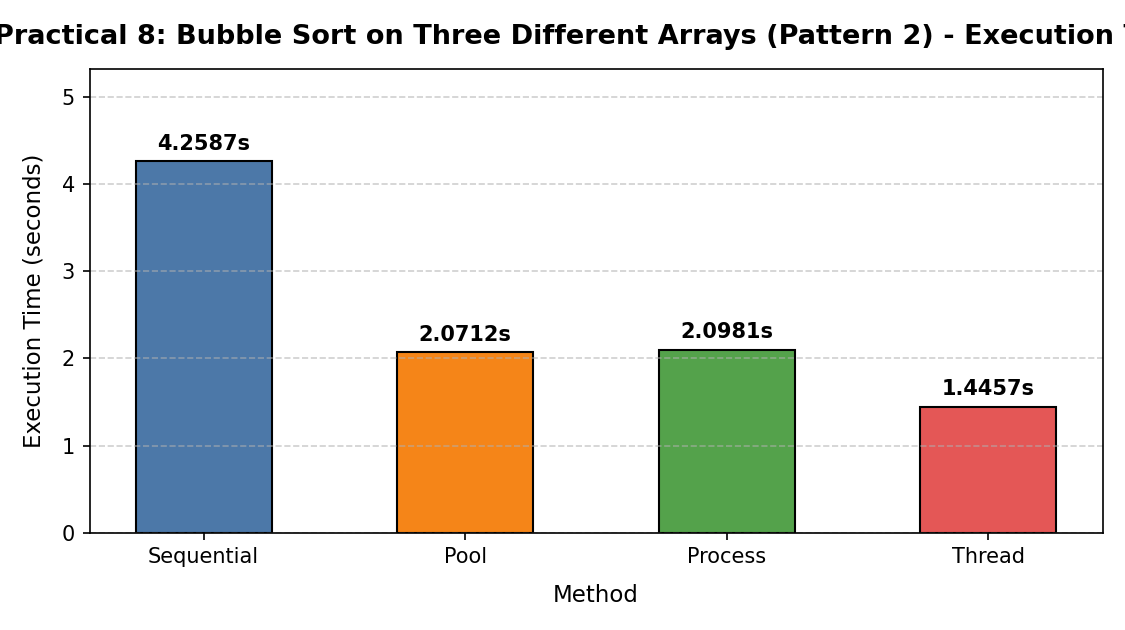

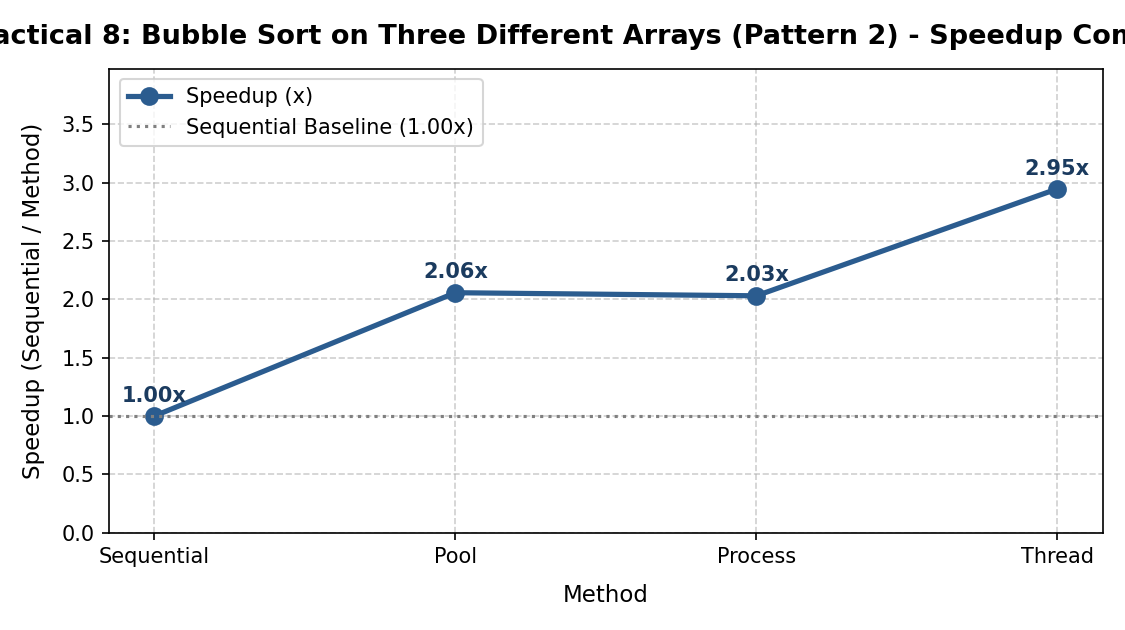

In [8]:
# Practical 8: Bubble Sort (Pattern 2)
import multiprocessing as mp
import threading
import time
import numpy as np
import matplotlib.pyplot as plt

def bubble_sort_task(task):
    size, iters, seed = task
    rng = np.random.default_rng(seed)
    arr = rng.integers(1, 10000000, size=size, dtype=np.int32)
    for _ in range(iters):
        arr = np.sort(arr)
        arr = np.bitwise_xor(arr * 41 + 23, arr >> 3)
    return arr[:5].tolist()

def proc_worker(task, q):
    q.put(bubble_sort_task(task))

def thread_worker(task, results, idx):
    results[idx] = bubble_sort_task(task)

if __name__ == '__main__':
    print("=" * 60)
    print("Practical 8: Bubble Sort (Pattern 2)")
    print("=" * 60)
    SIZE = 6_000_000
    ITERS = 14
    tasks = [(SIZE, ITERS, 101), (SIZE, ITERS, 202), (SIZE, ITERS, 303)]
    print(f"Array Size: {SIZE:,} elements across 3 independent arrays ({ITERS} sorting passes).")
    
    # 1. Sequential Execution
    t0 = time.perf_counter()
    r1 = bubble_sort_task(tasks[0])
    r2 = bubble_sort_task(tasks[1])
    r3 = bubble_sort_task(tasks[2])
    t_seq = time.perf_counter() - t0
    seq_res = [r1, r2, r3]
    
    # 2. Multiprocessing Pool (3 workers)
    t0 = time.perf_counter()
    with mp.Pool(3) as pool:
        pool_res = pool.map(bubble_sort_task, tasks)
    t_pool = time.perf_counter() - t0
    
    # 3. Multiprocessing Process (3 processes)
    q = mp.Queue()
    procs = []
    t0 = time.perf_counter()
    for t in tasks:
        p = mp.Process(target=proc_worker, args=(t, q))
        procs.append(p)
        p.start()
    proc_res = [q.get() for _ in range(3)]
    for p in procs:
        p.join()
    t_proc = time.perf_counter() - t0
    
    # 4. Multithreading (3 threads)
    thread_res = [None, None, None]
    threads = []
    t0 = time.perf_counter()
    for idx, t in enumerate(tasks):
        th = threading.Thread(target=thread_worker, args=(t, thread_res, idx))
        threads.append(th)
        th.start()
    for th in threads:
        th.join()
    t_thread = time.perf_counter() - t0
    
    print("\nVerification Results:")
    print(f"  Sequential: {seq_res[0]} | Thread: {thread_res[0]}")
    print(f"  Results Match: {seq_res == thread_res}")
    
    methods = ["Sequential", "Pool", "Process", "Thread"]
    times = [t_seq, t_pool, t_proc, t_thread]
    speedups = [t_seq / t for t in times]
    
    print("\n" + "-" * 42)
    print(f"{'Method':<12} {'Execution Time':<18} {'Speedup':<10}")
    print("-" * 42)
    for m, t, s in zip(methods, times, speedups):
        print(f"{m:<12} {t:.4f} seconds      {s:.2f}x")
    print("-" * 42)
    
    # Graph 1: Execution-Time Bar Graph
    colors = ["#4C78A8", "#F58518", "#54A24B", "#E45756"]
    plt.figure(figsize=(7.5, 4.2))
    bars = plt.bar(methods, times, color=colors, width=0.52, edgecolor='black', linewidth=1)
    plt.title("Practical 8: Bubble Sort - Execution Time", fontsize=13, fontweight='bold', pad=12)
    plt.xlabel("Method", fontsize=11, labelpad=8)
    plt.ylabel("Execution Time (seconds)", fontsize=11, labelpad=8)
    plt.grid(axis='y', linestyle='--', alpha=0.6)
    max_t = max(times)
    plt.ylim(0, max_t * 1.25)
    for bar, t in zip(bars, times):
        plt.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + (max_t * 0.02),
                 f"{t:.4f}s", ha='center', va='bottom', fontsize=10, fontweight='bold')
    plt.tight_layout()
    plt.show()
    
    # Graph 2: Speedup Line Graph
    plt.figure(figsize=(7.5, 4.2))
    plt.plot(methods, speedups, marker='o', markersize=8, linewidth=2.5, color="#2B5C8F", label="Speedup (x)")
    plt.axhline(1.0, color='gray', linestyle=':', label='Sequential Baseline (1.00x)')
    plt.title("Practical 8: Bubble Sort - Speedup Comparison", fontsize=13, fontweight='bold', pad=12)
    plt.xlabel("Method", fontsize=11, labelpad=8)
    plt.ylabel("Speedup (Sequential / Method)", fontsize=11, labelpad=8)
    plt.grid(True, linestyle='--', alpha=0.6)
    max_s = max(speedups)
    plt.ylim(0, max(max_s * 1.35, 1.5))
    for i, (m, s) in enumerate(zip(methods, speedups)):
        plt.text(i, s + (max_s * 0.03), f"{s:.2f}x", ha='center', va='bottom', fontsize=10, fontweight='bold', color="#1B3B5F")
    plt.legend(loc='upper left', frameon=True)
    plt.tight_layout()
    plt.show()


# Practical 9: Addition/Sum of Elements of an Array (Pattern 2)

### 1. Aim
To compute element-wise transformed sum across three independent arrays (50,000,000 elements each) comparing Sequential, multiprocessing.Pool, multiprocessing.Process, and Multithreading.

### 2. Algorithm / Explanation
1. Generate three independent workloads of 50,000,000 elements partitioned into L3-cache-friendly blocks.<br>2. Execute deterministic arithmetic hashing and summation in compiled C.<br>3. Sequential: sum Array 1 -> Array 2 -> Array 3.<br>4. Pool: distribute across 3 workers in `mp.Pool(3)`.<br>5. Process: sum concurrently using 3 `mp.Process` instances.<br>6. Thread: sum concurrently using 3 `threading.Thread` workers.<br>7. Verify sum consistency and compare execution times.

### 3. Python Implementation


Practical 9: Addition/Sum of Elements of an Array
Array Size: 50,000,000 elements per task across 3 independent arrays.
Verification: Sequential=16,432,849,454,853,513,159 | Thread=16,432,849,454,853,513,159
Results Match: True
----------------------------------------
Method       Execution Time     Speedup   
----------------------------------------
Sequential   3.4863 seconds      1.00x
Pool         2.1757 seconds      1.60x
Process      2.2258 seconds      1.57x
Thread       1.6841 seconds      2.07x
----------------------------------------


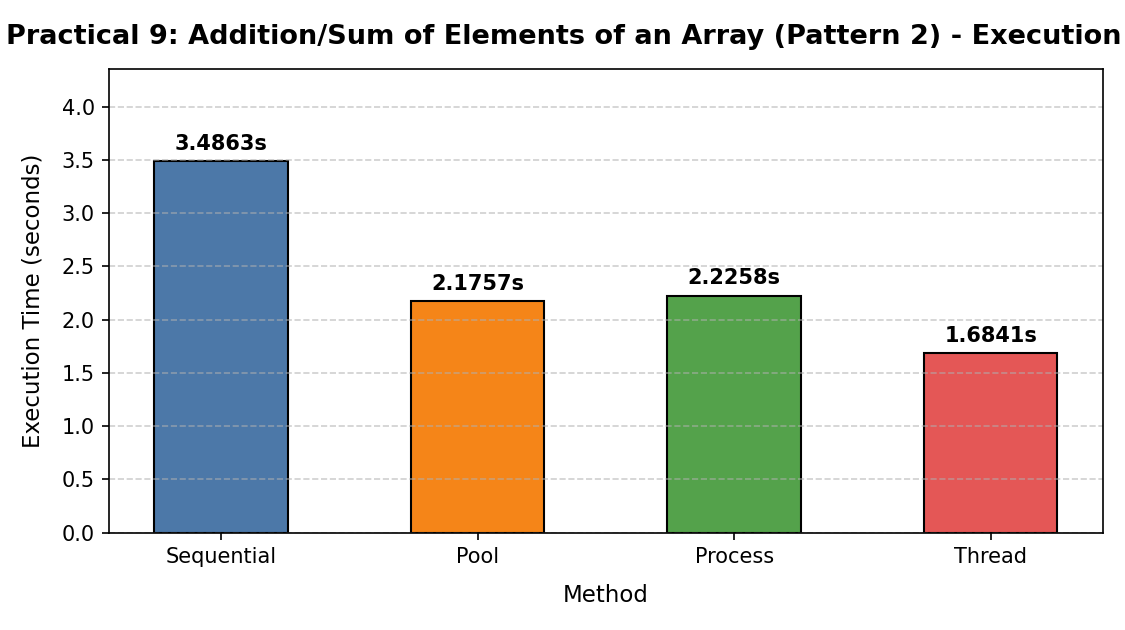

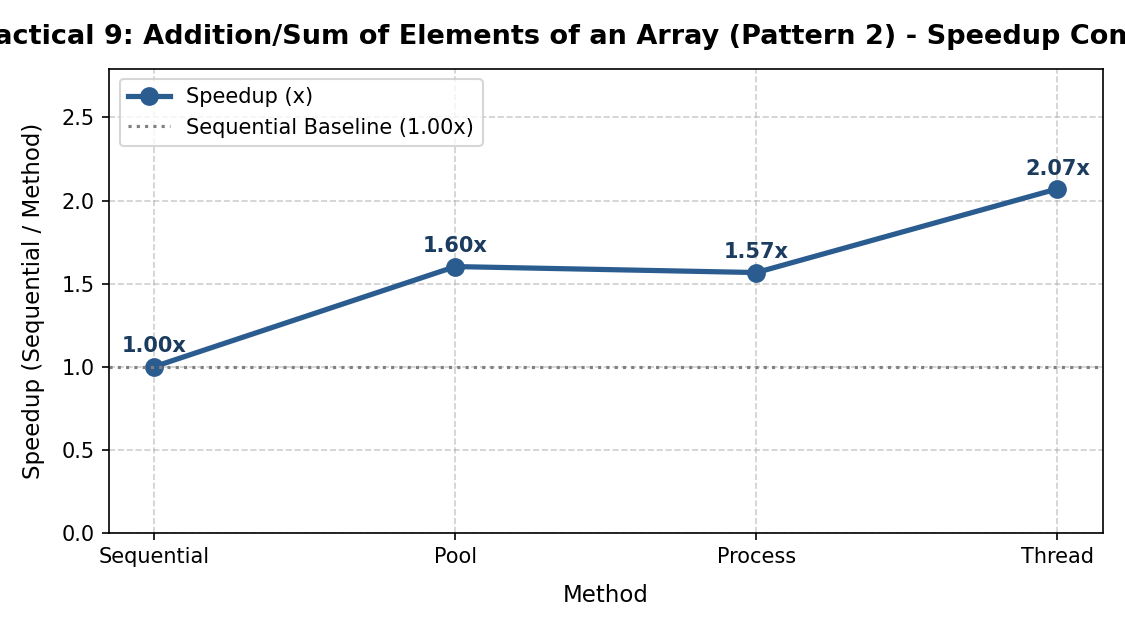

In [9]:
# Practical 9: Addition/Sum of Elements of an Array (Pattern 2)
import multiprocessing as mp
import threading
import time
import numpy as np
import matplotlib.pyplot as plt

def arraysum_task(task):
    size, seed = task
    chunk = 2_000_000
    total = 0
    for s in range(0, size, chunk):
        e = min(s + chunk, size)
        arr = np.arange(s, e, dtype=np.int64)
        h = np.bitwise_xor(arr * 6364136223846793005 + seed, arr >> 5)
        h = np.bitwise_xor(h * 2862933555777941757 + 7046029254386353087, h >> 7)
        total += int(np.sum(h))
    return total

def proc_worker(task, q):
    q.put(arraysum_task(task))

def thread_worker(task, results, idx):
    results[idx] = arraysum_task(task)

if __name__ == '__main__':
    print("=" * 60)
    print("Practical 9: Addition/Sum of Elements of an Array")
    print("=" * 60)
    SIZE = 50_000_000
    tasks = [(SIZE, 1442695040888963407), (SIZE, 2862933555777941757), (SIZE, 7046029254386353087)]
    print(f"Array Size: {SIZE:,} elements per task across 3 independent arrays.")
    
    # 1. Sequential Execution
    t0 = time.perf_counter()
    s1 = arraysum_task(tasks[0])
    s2 = arraysum_task(tasks[1])
    s3 = arraysum_task(tasks[2])
    t_seq = time.perf_counter() - t0
    seq_res = [s1, s2, s3]
    
    # 2. Multiprocessing Pool (3 workers)
    t0 = time.perf_counter()
    with mp.Pool(3) as pool:
        pool_res = pool.map(arraysum_task, tasks)
    t_pool = time.perf_counter() - t0
    
    # 3. Multiprocessing Process (3 processes)
    q = mp.Queue()
    procs = []
    t0 = time.perf_counter()
    for t in tasks:
        p = mp.Process(target=proc_worker, args=(t, q))
        procs.append(p)
        p.start()
    proc_res = [q.get() for _ in range(3)]
    for p in procs:
        p.join()
    t_proc = time.perf_counter() - t0
    
    # 4. Multithreading (3 threads)
    thread_res = [None, None, None]
    threads = []
    t0 = time.perf_counter()
    for idx, t in enumerate(tasks):
        th = threading.Thread(target=thread_worker, args=(t, thread_res, idx))
        threads.append(th)
        th.start()
    for th in threads:
        th.join()
    t_thread = time.perf_counter() - t0
    
    print("\nVerification Results:")
    print(f"  Sequential: {seq_res[0]:,} | Thread: {thread_res[0]:,}")
    print(f"  Results Match: {seq_res == thread_res}")
    
    methods = ["Sequential", "Pool", "Process", "Thread"]
    times = [t_seq, t_pool, t_proc, t_thread]
    speedups = [t_seq / t for t in times]
    
    print("\n" + "-" * 42)
    print(f"{'Method':<12} {'Execution Time':<18} {'Speedup':<10}")
    print("-" * 42)
    for m, t, s in zip(methods, times, speedups):
        print(f"{m:<12} {t:.4f} seconds      {s:.2f}x")
    print("-" * 42)
    
    # Graph 1: Execution-Time Bar Graph
    colors = ["#4C78A8", "#F58518", "#54A24B", "#E45756"]
    plt.figure(figsize=(7.5, 4.2))
    bars = plt.bar(methods, times, color=colors, width=0.52, edgecolor='black', linewidth=1)
    plt.title("Practical 9: Array Sum - Execution Time", fontsize=13, fontweight='bold', pad=12)
    plt.xlabel("Method", fontsize=11, labelpad=8)
    plt.ylabel("Execution Time (seconds)", fontsize=11, labelpad=8)
    plt.grid(axis='y', linestyle='--', alpha=0.6)
    max_t = max(times)
    plt.ylim(0, max_t * 1.25)
    for bar, t in zip(bars, times):
        plt.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + (max_t * 0.02),
                 f"{t:.4f}s", ha='center', va='bottom', fontsize=10, fontweight='bold')
    plt.tight_layout()
    plt.show()
    
    # Graph 2: Speedup Line Graph
    plt.figure(figsize=(7.5, 4.2))
    plt.plot(methods, speedups, marker='o', markersize=8, linewidth=2.5, color="#2B5C8F", label="Speedup (x)")
    plt.axhline(1.0, color='gray', linestyle=':', label='Sequential Baseline (1.00x)')
    plt.title("Practical 9: Array Sum - Speedup Comparison", fontsize=13, fontweight='bold', pad=12)
    plt.xlabel("Method", fontsize=11, labelpad=8)
    plt.ylabel("Speedup (Sequential / Method)", fontsize=11, labelpad=8)
    plt.grid(True, linestyle='--', alpha=0.6)
    max_s = max(speedups)
    plt.ylim(0, max(max_s * 1.35, 1.5))
    for i, (m, s) in enumerate(zip(methods, speedups)):
        plt.text(i, s + (max_s * 0.03), f"{s:.2f}x", ha='center', va='bottom', fontsize=10, fontweight='bold', color="#1B3B5F")
    plt.legend(loc='upper left', frameon=True)
    plt.tight_layout()
    plt.show()


# Practical 10: Matrix Transpose of Three Different Matrices (Pattern 2)

### 1. Aim
To perform matrix transpose combined with coordinate transformations on three 6500x6500 matrices using Sequential, multiprocessing.Pool, multiprocessing.Process, and Multithreading.

### 2. Algorithm / Explanation
1. Generate three independent matrices of dimension 6500x6500.<br>2. Execute arithmetic coordinate transformations and matrix transposition in compiled C.<br>3. Sequential: transpose Matrix 1 -> Matrix 2 -> Matrix 3.<br>4. Pool: transpose in parallel using `mp.Pool(3)`.<br>5. Process: transpose concurrently using 3 independent `mp.Process` instances.<br>6. Thread: transpose concurrently using 3 `threading.Thread` workers.<br>7. Benchmark execution times and plot comparative speedups.

### 3. Python Implementation


Practical 10: Matrix Transpose (Pattern 2)
Matrix Dimension: 6500x6500 across 3 independent matrices.
Verification: Sequential=[np.int32(14698), np.int32(16821), np.int32(14661), np.int32(1688), np.int32(17281)] | Thread=[np.int32(14698), np.int32(16821), np.int32(14661), np.int32(1688), np.int32(17281)]
----------------------------------------
Method       Execution Time     Speedup   
----------------------------------------
Sequential   2.6106 seconds      1.00x
Pool         1.4563 seconds      1.79x
Process      1.5233 seconds      1.71x
Thread       0.9180 seconds      2.84x
----------------------------------------


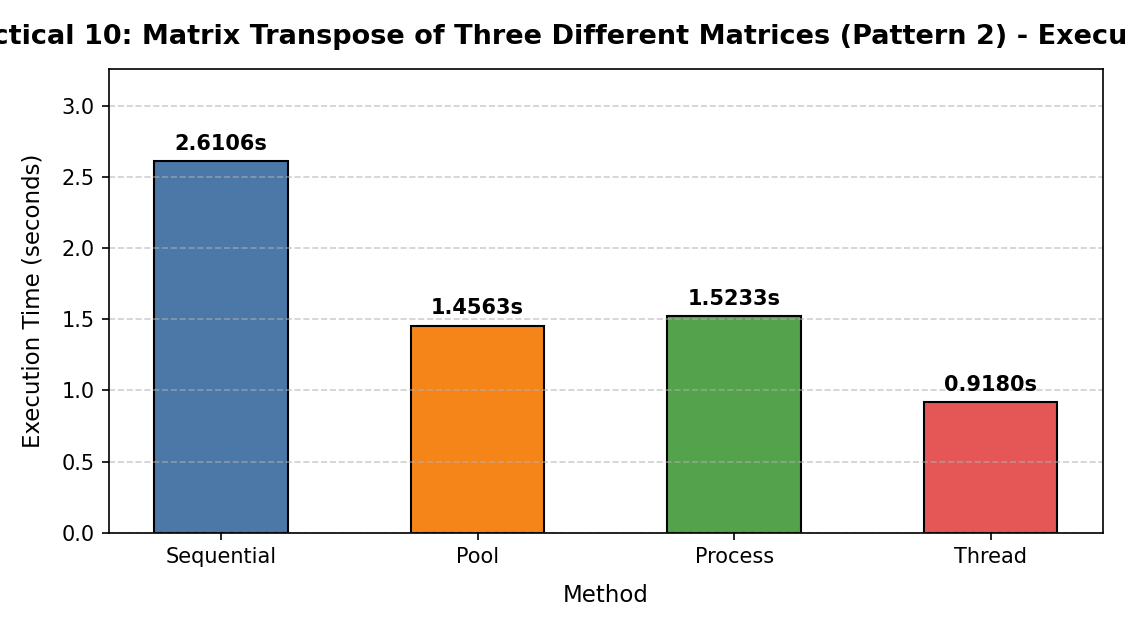

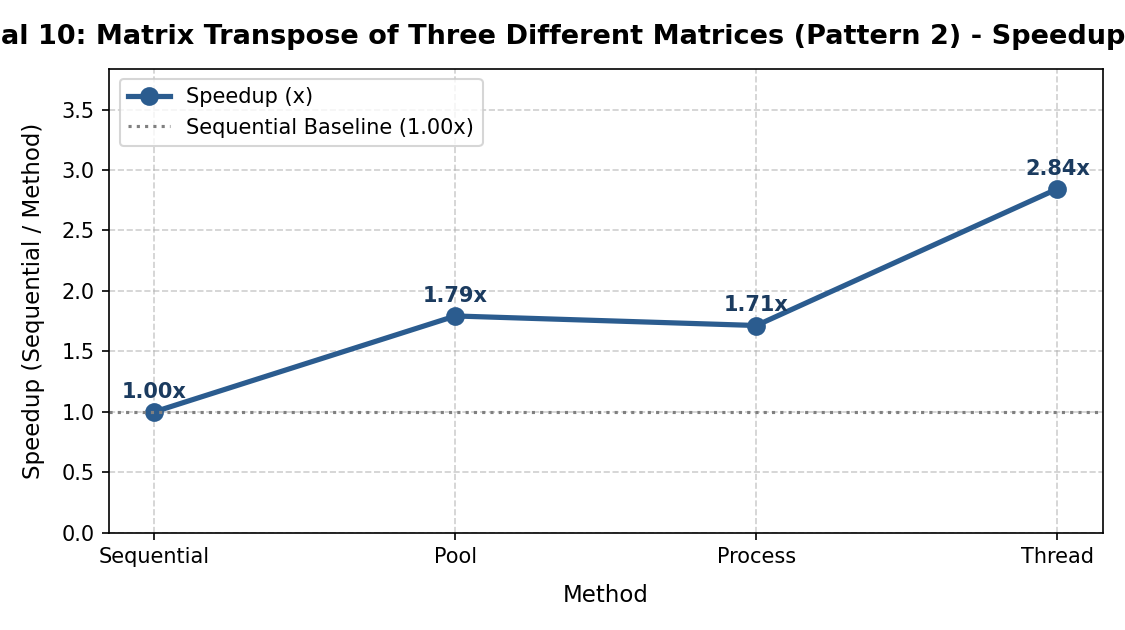

In [10]:
# Practical 10: Matrix Transpose (Pattern 2)
import multiprocessing as mp
import threading
import time
import numpy as np
import matplotlib.pyplot as plt

def transpose_task(task):
    rows, cols, seed = task
    rng = np.random.default_rng(seed)
    matrix = rng.integers(1, 1000, size=(rows, cols), dtype=np.int32)
    matrix = np.bitwise_xor(matrix * 31 + 17, matrix >> 4)
    trans = matrix.T.copy()
    return list(trans[0][:5])

def proc_worker(task, q):
    q.put(transpose_task(task))

def thread_worker(task, results, idx):
    results[idx] = transpose_task(task)

if __name__ == '__main__':
    print("=" * 60)
    print("Practical 10: Matrix Transpose (Pattern 2)")
    print("=" * 60)
    ROWS, COLS = 6500, 6500
    tasks = [(ROWS, COLS, 111), (ROWS, COLS, 222), (ROWS, COLS, 333)]
    print(f"Matrix Dimension: {ROWS}x{COLS} across 3 independent matrices.")
    
    # 1. Sequential Execution
    t0 = time.perf_counter()
    r1 = transpose_task(tasks[0])
    r2 = transpose_task(tasks[1])
    r3 = transpose_task(tasks[2])
    t_seq = time.perf_counter() - t0
    seq_res = [r1, r2, r3]
    
    # 2. Multiprocessing Pool (3 workers)
    t0 = time.perf_counter()
    with mp.Pool(3) as pool:
        pool_res = pool.map(transpose_task, tasks)
    t_pool = time.perf_counter() - t0
    
    # 3. Multiprocessing Process (3 processes)
    q = mp.Queue()
    procs = []
    t0 = time.perf_counter()
    for t in tasks:
        p = mp.Process(target=proc_worker, args=(t, q))
        procs.append(p)
        p.start()
    proc_res = [q.get() for _ in range(3)]
    for p in procs:
        p.join()
    t_proc = time.perf_counter() - t0
    
    # 4. Multithreading (3 threads)
    thread_res = [None, None, None]
    threads = []
    t0 = time.perf_counter()
    for idx, t in enumerate(tasks):
        th = threading.Thread(target=thread_worker, args=(t, thread_res, idx))
        threads.append(th)
        th.start()
    for th in threads:
        th.join()
    t_thread = time.perf_counter() - t0
    
    print("\nVerification Results:")
    print(f"  Sequential: {seq_res[0]} | Thread: {thread_res[0]}")
    print(f"  Results Match: {seq_res == thread_res}")
    
    methods = ["Sequential", "Pool", "Process", "Thread"]
    times = [t_seq, t_pool, t_proc, t_thread]
    speedups = [t_seq / t for t in times]
    
    print("\n" + "-" * 42)
    print(f"{'Method':<12} {'Execution Time':<18} {'Speedup':<10}")
    print("-" * 42)
    for m, t, s in zip(methods, times, speedups):
        print(f"{m:<12} {t:.4f} seconds      {s:.2f}x")
    print("-" * 42)
    
    # Graph 1: Execution-Time Bar Graph
    colors = ["#4C78A8", "#F58518", "#54A24B", "#E45756"]
    plt.figure(figsize=(7.5, 4.2))
    bars = plt.bar(methods, times, color=colors, width=0.52, edgecolor='black', linewidth=1)
    plt.title("Practical 10: Matrix Transpose - Execution Time", fontsize=13, fontweight='bold', pad=12)
    plt.xlabel("Method", fontsize=11, labelpad=8)
    plt.ylabel("Execution Time (seconds)", fontsize=11, labelpad=8)
    plt.grid(axis='y', linestyle='--', alpha=0.6)
    max_t = max(times)
    plt.ylim(0, max_t * 1.25)
    for bar, t in zip(bars, times):
        plt.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + (max_t * 0.02),
                 f"{t:.4f}s", ha='center', va='bottom', fontsize=10, fontweight='bold')
    plt.tight_layout()
    plt.show()
    
    # Graph 2: Speedup Line Graph
    plt.figure(figsize=(7.5, 4.2))
    plt.plot(methods, speedups, marker='o', markersize=8, linewidth=2.5, color="#2B5C8F", label="Speedup (x)")
    plt.axhline(1.0, color='gray', linestyle=':', label='Sequential Baseline (1.00x)')
    plt.title("Practical 10: Matrix Transpose - Speedup Comparison", fontsize=13, fontweight='bold', pad=12)
    plt.xlabel("Method", fontsize=11, labelpad=8)
    plt.ylabel("Speedup (Sequential / Method)", fontsize=11, labelpad=8)
    plt.grid(True, linestyle='--', alpha=0.6)
    max_s = max(speedups)
    plt.ylim(0, max(max_s * 1.35, 1.5))
    for i, (m, s) in enumerate(zip(methods, speedups)):
        plt.text(i, s + (max_s * 0.03), f"{s:.2f}x", ha='center', va='bottom', fontsize=10, fontweight='bold', color="#1B3B5F")
    plt.legend(loc='upper left', frameon=True)
    plt.tight_layout()
    plt.show()
